# Dry Run: Which Grape Is in the Glass?

*Can a model guess a wine's grape from a tasting note, and what is left when we take the obvious clues out?*

**Course:** Machine Learning, NaUKMA (mini-project)

**Team:** Alina Brukhanska, Milena Mashchenko, Viktoriia Boriak

## The short version

Wine reviewers love to name-drop. A tasting note might say *"this Riesling..."*, mention a valley, or tell you which winery made the bottle. A model that picks up on those words is not tasting anything. It is just reading the label.

So we ask a simple question: **if we strip those clues out of the reviews one step at a time, how much can a model still tell about the grape?**

Here is the plan, in four moves:

1. Take reviews of five grapes from the Wine Reviews dataset.
2. Make four versions of every review, from the original text (**L0**) to a text with grape names, other grapes, places and winery names removed (**L3**).
3. Train three classic models on each version, using the same data and the same folds for all of them.
4. Watch how the score changes, look at where the models go wrong, and say honestly what we can and cannot conclude.

This is not a hunt for the highest accuracy. What matters is that the experiment is fair, and that our conclusions only claim what the evidence supports.

## How this notebook is organized

We will have eleven steps. Each one has a home in the notebook, so you can find it without hunting. Sections marked **here** are in this part of the notebook. The rest are coming next.

| Section | What happens | Course step | Status |
|---|---|---|---|
| 1. The question | Main question, sub-questions, hypotheses, the plan at a glance | 1. Formulate the question | here |
| 2. Setup | Packages, imports, seed, folders, library versions | 11. Reproducibility | here |
| 3. The data | Source, license, loading, first look | 2. Inspect the data | here |
| 4. Cleaning and the shared sample | Remove missing values and duplicates, pick five grapes, balance the classes | 2. Inspect the data |here|
| 5. Splits and folds | DEV / MAIN split by winery, shared cross-validation folds | 6. Validation scheme |here |
| 6. Masking L0 to L3 | Word lists and the four text versions | 4. Preprocessing | next |
| 7. Metrics and baselines | Macro-F1 and friends, dummy baselines | 3. Baseline, 7. Metrics | next |
| 8. The three models | Pipelines, small tuning grids on DEV | 5. Models | next |
| 9. Results | One table, plots, extra checks | 8. Compare experiments | next |
| 10. Errors | Confusion matrices, top words, real examples | 9. Error analysis | next |
| 11. Conclusions | What we found, and the limits | 10. Limitations and conclusions | next |

## 1. The question *(course step 1)*

### Main question

> How well can we tell one of five grape varieties from the text of a tasting note, and how does that change when we remove the obvious clues one layer at a time?

The five grapes are **Chardonnay, Riesling, Pinot Noir, Cabernet Sauvignon and Syrah**. Two are white and three are red, which gives us something interesting to look at later in the mistakes.

### Sub-questions

- **RQ1. Masking.** How does the macro-F1 score move from L0 to L1 to L2 to L3? Do all three models react the same way? Which step hurts the most?
- **RQ2. Validation scheme** *(extra experiment)*. How different does logistic regression look under ordinary random cross-validation versus cross-validation that keeps each winery on one side only?
- **RQ3. Mistakes.** Which grapes get mixed up, and does that change after masking? Are reds mistaken for other reds more often than for whites?
- **RQ4. Words.** Which words push logistic regression towards each grape, on L0 and on L3? Are there still obvious clues left, and which taste words show up?
- **RQ5. Metadata** *(extra experiment)*. How far can we get using only geography, or only the taster's name, with no review text at all?

### What we expect (written down before we run anything)

- **H1.** Masking lowers the score on average, but the score stays above a random-guess baseline. It may not drop at every single step.
- **H2.** The last step, L2 to L3, changes the score noticeably. It removes places and winery names at the same time, so we will not be able to say which of the two matters more.
- **H3.** Reds get confused with other reds more than with whites.
- **H4.** Random cross-validation gives a higher score than winery-grouped cross-validation. A tiny difference, or the opposite, would also be a real result.
- **H5.** Logistic regression holds its own against the more complex SVD + boosting model. The simple model may well be enough.

If a hypothesis turns out wrong, that is a finding, not a failure.

### What counts as an answer

One main table: three models by four text versions, showing mean and standard deviation of macro-F1 over the same folds, with the baseline next to it. Then per-grape scores, confusion matrices, a handful of real mistakes read by hand, and a short conclusion for each question we actually ran.

### What we are *not* claiming

We sort reviews into five known grapes. We do not test whether a model can spot an unknown grape, measure how a wine really tastes, or show that a model "understands" flavor. Even after L3, hints can survive: indirect names, regional style, the way a particular taster writes. A score above the baseline on L3 does not prove the model learned to taste.

### The plan at a glance *(course steps 3 to 7)*

#### Four versions of every review

| Version | What we remove | What it tells us |
|---|---|---|
| **L0** | Nothing special, only basic cleanup shared by all versions | How well models do on the original text |
| **L1** | The five target grape names and their spelling variants | What changes without the direct answer |
| **L2** | Also the names of other grapes, from a fixed word list | Whether mentions of other grapes help |
| **L3** | Also place names, "where it's from" adjectives, and this review's own winery name | What is left after the widest masking |

The word lists are prepared before we run the experiments and do not depend on model results. Taste words such as *petrol*, *tannin* or *oak* are never removed just because they happen to go with a grape.

#### Three models, and why each one is here

| Model | Why it is in the study |
|---|---|
| TF-IDF + **Logistic Regression** | The readable one. Its coefficients show which words go with which grape. |
| TF-IDF + **Complement Naive Bayes** | Fast, built differently, and a classic for text. Shows whether we need anything fancier. |
| TF-IDF + **Truncated SVD** + **Hist Gradient Boosting** | A non-linear check. Does squeezing the text down and adding a more flexible model help? |

#### How we keep the test honest

- **Baselines.** Two dummy classifiers (always the most frequent class, and random guessing that follows class frequencies), scored on the same folds as everything else.
- **Group by winery.** Reviews from one winery share vocabulary and style. If some land in training and others in testing, the model can win by recognizing the winery. So each winery stays on one side of every split.
- **DEV and MAIN.** About a quarter of the wineries go to DEV, and we use it only for tuning. The rest is MAIN, where the final comparison happens. Once we have seen MAIN scores, we do not go back and tune.
- **No peeking.** TF-IDF and SVD live inside a scikit-learn `Pipeline`, so they are fitted from scratch on the training part of every fold and never see the test part.
- **Metric.** Macro-F1 is our main number because it treats all five grapes equally. We also report balanced accuracy and per-grape precision, recall and F1.
- **Folds.** Five folds, repeated three times if the running time allows. All models share the exact same folds. We decide on the number of repeats after timing things on DEV, before we touch MAIN. Anything we change after seeing MAIN scores gets labeled as after-the-fact.

## 2. Setup *(course step 11)*

This part runs on a normal laptop CPU. No GPU is needed. It checks that the packages are installed, loads them, and writes down which versions we used.

### 2.1 Are the packages here?

We only check. We do not reinstall anything, so Colab's own setup stays untouched. If something is missing, the message tells you what to install. Run the install in its own cell *before* the imports, and restart the runtime if you updated a package that was already loaded.

In [1]:
from importlib.util import find_spec

CORE_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "scikit-learn": "sklearn",
    "matplotlib": "matplotlib",
}

missing_packages = [
    package for package, module in CORE_PACKAGES.items()
    if find_spec(module) is None
]

if missing_packages:
    raise ModuleNotFoundError(
        "Some packages are missing. Run this in a separate cell first:\n"
        "%pip install " + " ".join(missing_packages)
    )

print("All core packages are installed.")

All core packages are installed.


### 2.2 Imports

Importing is all we do here. No model is trained in this section.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
import hashlib
import json
import platform
import random
import re
import textwrap

# Data and plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn pieces
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (
    GroupShuffleSplit, StratifiedGroupKFold, StratifiedKFold, GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    log_loss, precision_recall_fscore_support,
)

print("Imports done. Nothing has been trained yet.")

Imports done. Nothing has been trained yet.


### 2.3 One place for all settings

Every setting the team agreed on lives in this one cell. If we change something, we change it here and nowhere else.

A couple of notes:

- `N_JOBS = 1` is a safe, slow-and-steady default. It does not promise bit-for-bit identical results on every machine.
- Fixing `random.seed` and `np.random.seed` is not enough on its own. Whenever a specific algorithm takes a `random_state`, we pass `SEED` to it directly.
- `DATA_STAGE = "raw"` means we start from the original Kaggle file. Once the team's shared sample exists, we switch to `"sample"` and everyone reads the same file.

In [3]:
# Settings agreed by the whole team
SEED = 42
CLASSES = ["Chardonnay", "Riesling", "Pinot Noir", "Cabernet Sauvignon", "Syrah"]
LEVELS = ["L0", "L1", "L2", "L3"]
MODEL_NAMES = ["LogReg", "CompNB", "SVD_HGB"]

SAMPLE_CAP = 3000           # at most this many reviews per grape
DEV_GROUP_FRACTION = 0.25   # share of wineries that go to DEV
N_SPLITS = 5                # folds in cross-validation
N_REPEATS = 3               # repeats of the whole cross-validation
N_JOBS = 1
PRIMARY_SCORING = "f1_macro"

# Where the data comes from
DATA_STAGE = "raw"          # "raw" = original Kaggle CSV, "sample" = our shared sample
RAW_SOURCE = "local"        # "local" = file already uploaded, "kaggle" = download with kagglehub
RAW_FILENAME = "winemag-data-130k-v2.csv"
KAGGLE_DATASET = "zynicide/wine-reviews"
KAGGLE_VERSION = 4          # Kaggle, "Version 4"
EXPECTED_RAW_SHA256 = "52af2643c8ac29f010f0cc629dfbdda1c74aa0f332d11762af9ef3de4e567ac9"

# Quick sanity checks so a typo does not cost us an hour later
if len(CLASSES) != 5 or len(set(CLASSES)) != 5:
    raise ValueError("We need exactly five different grape classes.")
if DATA_STAGE not in {"raw", "sample"}:
    raise ValueError("DATA_STAGE must be 'raw' or 'sample'.")
if RAW_SOURCE not in {"local", "kaggle"}:
    raise ValueError("RAW_SOURCE must be 'local' or 'kaggle'.")
if not 0 < DEV_GROUP_FRACTION < 1:
    raise ValueError("DEV_GROUP_FRACTION must be between 0 and 1.")
if N_SPLITS < 2 or N_REPEATS < 1 or SAMPLE_CAP < 1:
    raise ValueError("N_SPLITS, N_REPEATS and SAMPLE_CAP have invalid values.")
if KAGGLE_VERSION is not None and (type(KAGGLE_VERSION) is not int or KAGGLE_VERSION < 1):
    raise ValueError("KAGGLE_VERSION must be a positive whole number, or None.")

random.seed(SEED)
np.random.seed(SEED)

print("Settings look fine. Seed:", SEED)
print("Grapes:", CLASSES)
print("Data mode:", DATA_STAGE, "/", RAW_SOURCE)

Settings look fine. Seed: 42
Grapes: ['Chardonnay', 'Riesling', 'Pinot Noir', 'Cabernet Sauvignon', 'Syrah']
Data mode: raw / local


### 2.4 Folders and plot style

Paths are relative to the folder the notebook runs from (in Colab that is usually `/content`). Nothing is searched for on your disk behind your back. Check the printed path to make sure it is what you expect.

Put the original CSV in that same folder. The shared sample will live in `data/`. The output folders below are created automatically.

In [4]:
PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data"
MASKING_DIR = PROJECT_ROOT / "masking"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
SETUP_DIR = RESULTS_DIR / "setup"

for directory in [DATA_DIR, MASKING_DIR, RESULTS_DIR, FIGURES_DIR, SETUP_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

RAW_LOCAL_PATH = PROJECT_ROOT / RAW_FILENAME
SAMPLE_PATH = DATA_DIR / "wine_sample.csv"
SAMPLE_HASH_PATH = DATA_DIR / "wine_sample.sha256"

# Display settings only. They change how things look, never the data.
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
PLOT_COLOR = "#2a78d6"   # one calm blue for single-series charts
INK = "#52514e"          # muted gray for annotations

print("Project folder:", PROJECT_ROOT)
print("Looking for the original CSV at:", RAW_LOCAL_PATH)
print("Shared sample will be at:", SAMPLE_PATH)

Project folder: /content
Looking for the original CSV at: /content/winemag-data-130k-v2.csv
Shared sample will be at: /content/data/wine_sample.csv


### 2.5 Which versions did we use?

Different library versions can give slightly different numbers, so we write down what is installed. This list is also the starting point for the `requirements.txt` we will submit. It is a record of this run, not proof that the whole project is reproducible. We will test that with a clean run at the end.

In [5]:
STARTED_AT_UTC = datetime.now(timezone.utc).isoformat()

version_rows = [
    {"package": package, "version": metadata.version(package)}
    for package in CORE_PACKAGES
]
if DATA_STAGE == "raw" and RAW_SOURCE == "kaggle":
    if find_spec("kagglehub") is None:
        raise ModuleNotFoundError(
            "RAW_SOURCE='kaggle' needs kagglehub. Run in a separate cell:\n"
            "%pip install -q kagglehub"
        )
    version_rows.append({"package": "kagglehub", "version": metadata.version("kagglehub")})

versions = pd.DataFrame(version_rows)
versions.to_csv(SETUP_DIR / "package_versions.csv", index=False)
(SETUP_DIR / "requirements.startup.txt").write_text(
    "\n".join(f"{r['package']}=={r['version']}" for r in version_rows) + "\n",
    encoding="utf-8",
)

STARTUP_INFO = {
    "started_at_utc": STARTED_AT_UTC,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": dict(zip(versions["package"], versions["version"])),
    "seed": SEED,
    "classes": CLASSES,
    "levels": LEVELS,
    "sample_cap": SAMPLE_CAP,
    "dev_group_fraction": DEV_GROUP_FRACTION,
    "n_splits": N_SPLITS,
    "n_repeats": N_REPEATS,
    "n_jobs": N_JOBS,
    "primary_scoring": PRIMARY_SCORING,
    "data_stage": DATA_STAGE,
    "raw_source": RAW_SOURCE if DATA_STAGE == "raw" else None,
}

print("Python:", platform.python_version())
print(versions.to_string(index=False))
print("\nSaved to", SETUP_DIR)

Python: 3.13.18
     package version
       numpy   2.1.3
      pandas   2.2.3
       scipy  1.16.3
scikit-learn   1.6.1
  matplotlib  3.10.0

Saved to /content/results/setup


## 3. The data *(course step 2)*

### Where it comes from

**Wine Reviews**, shared on Kaggle by zynicide (Zack Thoutt): https://www.kaggle.com/datasets/zynicide/wine-reviews

According to the dataset page, the reviews were scraped from WineEnthusiast in June 2017, and scraped again on 22 November 2017. The file we use comes from the second scrape. That date tells us when the data was gathered, not when each review was written. We use the file `winemag-data-130k-v2.csv`.

The dataset page lists the license as **CC BY-NC-SA 4.0** (https://creativecommons.org/licenses/by-nc-sa/4.0/). If we share our sample, we keep the credit, the license and a note about what we changed.

### What each column is for

| Column | How we use it |
|---|---|
| `description` | **The input.** The text our models read. |
| `variety` | **The target.** The grape we are trying to predict. |
| `winery` | Used to group reviews when splitting, and as the winery name to mask on L3. The models never receive it as a feature. |
| `country`, `province`, `region_1`, `region_2` | For looking at the data and for the extra geography-only experiment. Not features of the main models. |
| `taster_name` | Only for the extra taster-only experiment. |
| `title`, `designation`, `points`, `price`, others | Left out of the main models. |

### How to get the file

- **Easiest:** download and unzip the CSV from Kaggle, then upload it with the Files panel in Colab into the folder printed in section 2.4. Keep `RAW_SOURCE = "local"`.
- **Or:** set `RAW_SOURCE = "kaggle"` and let `kagglehub` download it. Never put a Kaggle token in the notebook or on GitHub. Use your environment's secrets instead.
- **Once our shared sample exists:** set `DATA_STAGE = "sample"`. Everyone then reads the same CSV and checks it against the same hash, and the original file is no longer needed.

In [6]:
# Find the input file. We only locate it here; reading and cleaning come later.
if DATA_STAGE == "sample":
    INPUT_PATH = SAMPLE_PATH
    source_handle = None
elif RAW_SOURCE == "local":
    INPUT_PATH = RAW_LOCAL_PATH
    source_handle = None
else:
    import kagglehub

    source_handle = KAGGLE_DATASET
    if KAGGLE_VERSION is not None:
        source_handle += f"/versions/{KAGGLE_VERSION}"
    INPUT_PATH = Path(kagglehub.dataset_download(source_handle)).resolve() / RAW_FILENAME

if not INPUT_PATH.is_file():
    if DATA_STAGE == "raw":
        hint = ("Upload the unzipped CSV into the project folder with the Files panel, "
                "or set RAW_SOURCE = 'kaggle'.")
    else:
        hint = "Get data/wine_sample.csv and data/wine_sample.sha256 from the team repository."
    raise FileNotFoundError(f"Could not find {INPUT_PATH}. {hint}")

print("Found input file:", INPUT_PATH)
print("Size in bytes:", INPUT_PATH.stat().st_size)
if source_handle is not None:
    print("Kaggle handle:", source_handle)
    if KAGGLE_VERSION is None:
        print("Note: no Kaggle version is pinned yet. Pin one before we submit.")

Found input file: /content/winemag-data-130k-v2.csv
Size in bytes: 52908706


### 3.1 A fingerprint of the file

A SHA-256 hash is a short fingerprint of a file's exact bytes. If even one character changes, the hash changes. It tells us we are all working with the same file. It says nothing about the data's quality or license.

- For the **original** CSV, we compute the hash and record it. If nobody has pasted a reference hash into `EXPECTED_RAW_SHA256` yet, this is just a note, not a check.
- For our **shared sample**, a reference `.sha256` file is required, and the notebook stops if the hashes differ. We never overwrite the reference file just to make the check pass.

In [7]:
def sha256_file(path):
    """Hash a file in chunks, so we never hold a second copy in memory."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


INPUT_SHA256 = sha256_file(INPUT_PATH)

if DATA_STAGE == "sample":
    if not SAMPLE_HASH_PATH.is_file():
        raise FileNotFoundError(f"The reference hash file is missing: {SAMPLE_HASH_PATH}")
    expected_hash = SAMPLE_HASH_PATH.read_text(encoding="utf-8").strip().lower()
else:
    expected_hash = EXPECTED_RAW_SHA256.strip().lower() if EXPECTED_RAW_SHA256 else None

if expected_hash is not None:
    if re.fullmatch(r"[0-9a-f]{64}", expected_hash) is None:
        raise ValueError("A SHA-256 hash has exactly 64 hex characters.")
    if INPUT_SHA256 != expected_hash:
        raise ValueError("The file's hash does not match the reference. Check the file version.")
    hash_status = "matched_reference"
else:
    hash_status = "recorded_without_reference"

print("SHA-256:", INPUT_SHA256)
print("Status:", hash_status)

SHA-256: 52af2643c8ac29f010f0cc629dfbdda1c74aa0f332d11762af9ef3de4e567ac9
Status: matched_reference


### 3.2 Loading the table

We read the CSV into `input_df` and change nothing. In particular, we do not use `index_col=0`: the extra `Unnamed: 0` column is shown first, and we remove it on purpose in the cleaning step.

This is a structure check, not cleaning. In the raw file, missing values and duplicates are expected, and the cleaning step will count them. In the shared sample, they would be a problem, so the notebook checks for that.

In [8]:
input_df = pd.read_csv(INPUT_PATH, encoding="utf-8-sig", low_memory=False)

if input_df.empty:
    raise ValueError("The CSV has no rows.")

REQUIRED_COLUMNS = {"description", "variety", "winery"}
missing_columns = REQUIRED_COLUMNS - set(input_df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

TARGET_COUNTS = input_df["variety"].value_counts().reindex(CLASSES, fill_value=0)
absent_classes = TARGET_COUNTS.index[TARGET_COUNTS.eq(0)].tolist()
if absent_classes:
    raise ValueError(f"These grapes are not in the file: {absent_classes}")

optional_columns = ["taster_name", "country", "province", "region_1", "region_2"]
missing_optional = [c for c in optional_columns if c not in input_df.columns]

if DATA_STAGE == "sample":
    # The shared sample must already be clean. These checks make sure of it.
    if "row_id" not in input_df.columns:
        raise ValueError("The sample needs a stable row_id column.")
    if input_df["row_id"].isna().any() or not input_df["row_id"].is_unique:
        raise ValueError("row_id must be filled in and unique.")
    if not input_df["variety"].isin(CLASSES).all():
        raise ValueError("The sample contains grapes outside our five classes.")
    for column in ["description", "variety", "winery"]:
        values = input_df[column]
        if values.isna().any() or values.astype(str).str.strip().eq("").any():
            raise ValueError(f"Empty values in required column '{column}'.")
    description_key = (input_df["description"].str.casefold()
                       .str.replace(r"\s+", " ", regex=True).str.strip())
    if description_key.duplicated().any():
        raise ValueError("The sample still has duplicate descriptions.")
    if TARGET_COUNTS.nunique() != 1 or TARGET_COUNTS.max() > SAMPLE_CAP:
        raise ValueError("Class counts in the sample do not match the agreed balancing.")
    print("Loaded the shared sample.")
else:
    print("Loaded the original, uncleaned file.")

if missing_optional:
    print("Heads up: these optional columns are not in the file:", missing_optional)

print("Rows:", len(input_df), "| Columns:", input_df.shape[1])
print("Column names:", input_df.columns.tolist())
input_df.head(3)

Loaded the original, uncleaned file.
Rows: 129971 | Columns: 14
Column names: ['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'taster_name', 'taster_twitter_handle', 'title', 'variety', 'winery']


,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimstone and dried herb. The palate isn't overl...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth while still structured. Firm tannins ar...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and rind dominate. Some green pineapple pok...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm


### 3.3 A first look

This subsection explores the original CSV and runs only in `raw`
mode. In `sample` mode, these cells are skipped; the frozen sample
is validated in Section 4.1.

In [9]:
# Inspect the original file only in raw mode.
if DATA_STAGE == "raw":
    schema_overview = pd.DataFrame({
        "column": input_df.columns,
        "dtype": [str(input_df[c].dtype) for c in input_df.columns],
        "missing_count": input_df.isna().sum().to_numpy(),
        "missing_share": input_df.isna().mean().round(4).to_numpy(),
    })

    schema_overview.to_csv(
        SETUP_DIR / "schema_raw.csv",
        index=False,
    )

    display(schema_overview)

else:
    print("Original-data exploration skipped in sample mode.")

,column,dtype,missing_count,missing_share
0,Unnamed: 0,int64,0,0.0000
1,country,object,63,0.0005
2,description,object,0,0.0000
3,designation,object,37465,0.2883
4,points,int64,0,0.0000
5,price,float64,8996,0.0692
6,province,object,63,0.0005
7,region_1,object,21247,0.1635
8,region_2,object,79460,0.6114
9,taster_name,object,26244,0.2019


**Our five grapes.** How many reviews does each have, and how many different wineries are behind them? The winery count matters because we will group by winery when we split. A grape with only a handful of wineries would make grouped splitting hard.

In [10]:
if DATA_STAGE == "raw":

    def clean_key(series):
        """Normalize winery names for descriptive counting only."""
        return (
            series.dropna()
            .astype(str)
            .str.casefold()
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

    five = input_df.loc[
        input_df["variety"].isin(CLASSES)
    ].copy()

    five["n_words"] = (
        five["description"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    target_overview = pd.DataFrame({"variety": CLASSES})

    target_overview["n_reviews"] = [
        int(five["variety"].eq(grape).sum())
        for grape in CLASSES
    ]

    target_overview["n_wineries"] = [
        clean_key(
            five.loc[five["variety"].eq(grape), "winery"]
        ).replace("", np.nan).nunique()
        for grape in CLASSES
    ]

    target_overview["reviews_per_winery"] = (
        target_overview["n_reviews"]
        / target_overview["n_wineries"]
    ).round(1)

    target_overview.to_csv(
        SETUP_DIR / "target_counts_raw.csv",
        index=False,
    )

    display(target_overview)

else:
    print("Original-data exploration skipped in sample mode.")

,variety,n_reviews,n_wineries,reviews_per_winery
0,Chardonnay,11753,3380,3.5
1,Riesling,5189,1041,5.0
2,Pinot Noir,13272,2658,5.0
3,Cabernet Sauvignon,9472,2918,3.2
4,Syrah,4142,1430,2.9


**Which labels count as our grapes?** We keep only reviews whose `variety` is exactly one of our five names. But the file also has look-alike labels: other names for the same grape, different grapes with a similar name, and blends. This table shows how many there are, so it is clear what we are leaving out.

In [11]:
# Which other labels look like one of our five grapes?
# "Look-alike" = a label that contains the grape's name (or a well-known second name)
# but is not exactly our label. We only keep reviews with the exact label.
# Inspect the original file only in raw mode.
if DATA_STAGE == "raw":
  LOOK_ALIKE_PATTERNS = {
      "Chardonnay": r"chardonnay",
      "Riesling": r"riesling",
      "Pinot Noir": r"pinot noir|pinot nero|sp[aä]tburgunder",
      "Cabernet Sauvignon": r"cabernet sauvignon|^cabernet$",
      "Syrah": r"syrah|shiraz|sirah",
  }
  SHOW_TOP = 10   # look-alike labels to print per grape; None = print all

  label_counts = input_df["variety"].value_counts()

  long_rows = []
  for grape, pattern in LOOK_ALIKE_PATTERNS.items():
      hits = label_counts[label_counts.index.str.contains(pattern, case=False, regex=True, na=False)]
      hits = hits.drop(index=grape, errors="ignore")
      for label, n in hits.items():
          long_rows.append({"grape": grape, "look_alike_label": label, "n_reviews": int(n)})

  look_alike_table = pd.DataFrame(long_rows, columns=["grape", "look_alike_label", "n_reviews"])
  look_alike_table.to_csv(SETUP_DIR / f"look_alike_labels_{DATA_STAGE}.csv", index=False)

  summary = (look_alike_table.groupby("grape")
            .agg(n_other_labels=("look_alike_label", "count"), n_reviews=("n_reviews", "sum"))
            .reindex(LOOK_ALIKE_PATTERNS.keys()).fillna(0).astype(int))
  print(summary.to_string())

  for grape in LOOK_ALIKE_PATTERNS:
      part = look_alike_table[look_alike_table["grape"] == grape]
      shown = part if SHOW_TOP is None else part.head(SHOW_TOP)
      print(f"\n{grape}: {len(part)} look-alike labels"
            + ("" if len(shown) == len(part) else f" (showing the {len(shown)} biggest)"))
      if len(shown):
          print(shown[["look_alike_label", "n_reviews"]].to_string(index=False))

else:
    print("Original-data exploration skipped in sample mode.")

                    n_other_labels  n_reviews
grape                                        
Chardonnay                      21        158
Riesling                         7         57
Pinot Noir                       5        275
Cabernet Sauvignon              22        649
Syrah                           44       2198

Chardonnay: 21 look-alike labels (showing the 10 biggest)
          look_alike_label  n_reviews
       Chardonnay-Viognier         35
   Chenin Blanc-Chardonnay         33
          Viura-Chardonnay         13
       Viognier-Chardonnay         12
Sauvignon Blanc-Chardonnay          8
       Chardonnay-Semillon          7
      Chardonnay-Sauvignon          6
          Pinot-Chardonnay          6
Chardonnay-Sauvignon Blanc          6
    Chardonnay-Pinot Blanc          5

Riesling: 7 look-alike labels
       look_alike_label  n_reviews
         Welschriesling         25
         White Riesling         13
  Johannisberg Riesling          9
Gewürztraminer-Riesling       

**What kind of look-alike is each label?** A table of names is not enough, because "same grape under another name" or "a different grape" is not something the data can tell us. It is wine knowledge, so we write it down by hand and give a source for every entry. Labels with a hyphen, such as *Syrah-Grenache*, are blends. Unclassified labels are printed for manual review. They remain
excluded under the exact-label rule, and the auxiliary label audit
must not be presented as complete while they remain unresolved.

Sources:
- [Syrah](https://en.wikipedia.org/wiki/Syrah): "Syrah, also known as Shiraz"; Petite Sirah is a different grape, a cross of Syrah and Peloursin.
- [Pinot noir](https://en.wikipedia.org/wiki/Pinot_noir): *Spätburgunder* (Germany) and *Pinot nero* (Italy) are other names for Pinot noir; *Schwarzriesling* is a name of Pinot Meunier, a different grape.
- [Riesling](https://en.wikipedia.org/wiki/Riesling): *White Riesling* and *Johannisberg Riesling* are other names for Riesling; Welschriesling is an unrelated variety (see also [Welschriesling](https://en.wikipedia.org/wiki/Welschriesling)).



In [12]:
# Hand-made classification of look-alike labels (sources are in the text cell above).
if DATA_STAGE == "raw":
  SAME_GRAPE_OTHER_NAME = {    # label in the file -> the class it belongs to
      "Shiraz": "Syrah",
      "Pinot Nero": "Pinot Noir",
      "Spätburgunder": "Pinot Noir",
      "White Riesling": "Riesling",
      "Johannisberg Riesling": "Riesling",
  }
  DIFFERENT_GRAPE = {          # label in the file -> what it is
      "Petite Sirah": "Durif, a cross of Syrah and Peloursin",
      "Welschriesling": "unrelated to Riesling",
      "Schwartzriesling": "a name of Pinot Meunier (the file spells it with a 't')",
  }


  def kind_of(label):
      if "-" in label:
          return "blend"
      if label in SAME_GRAPE_OTHER_NAME:
          return "same grape, other name"
      if label in DIFFERENT_GRAPE:
          return "different grape"
      return "UNCLASSIFIED"


  look_alike_table["kind"] = look_alike_table["look_alike_label"].map(kind_of)
  look_alike_table.to_csv(SETUP_DIR / f"look_alike_labels_{DATA_STAGE}.csv", index=False)

  # Reviews per kind. A blend of two of our grapes appears under both, so rows are not additive.
  kind_summary = (look_alike_table
                  .pivot_table(index="grape", columns="kind", values="n_reviews",
                              aggfunc="sum", fill_value=0)
                  .reindex(CLASSES).fillna(0).astype(int))
  kind_summary.insert(0, "exact_label", TARGET_COUNTS.reindex(CLASSES).astype(int))
  print("Reviews by kind of look-alike label")
  print(kind_summary.to_string())

  # What would we gain if we merged the same-grape names into our classes?
  extra = (look_alike_table[look_alike_table["kind"] == "same grape, other name"]
          .groupby("grape")["n_reviews"].sum().reindex(CLASSES, fill_value=0))
  merge_check = pd.DataFrame({
      "exact_label": TARGET_COUNTS.reindex(CLASSES).astype(int),
      "extra_if_merged": extra.astype(int),
  })
  merge_check["extra_percent"] = (100 * merge_check["extra_if_merged"]
                                  / merge_check["exact_label"]).round(1)
  merge_check["enough_without_merging"] = merge_check["exact_label"] >= SAMPLE_CAP
  print("\nWould merging same-grape names help us reach the cap?")
  print(merge_check.to_string())

  unclassified = look_alike_table[look_alike_table["kind"] == "UNCLASSIFIED"]
  if len(unclassified):
      print("\nPlease classify these labels by hand before we continue:")
      print(unclassified[["grape", "look_alike_label", "n_reviews"]].to_string(index=False))
  else:
      print("\nEvery look-alike label is classified.")

else:
    print("Original-data exploration skipped in sample mode.")

Reviews by kind of look-alike label
kind                exact_label  UNCLASSIFIED  blend  different grape  same grape, other name
grape                                                                                        
Chardonnay                11753             2    156                0                       0
Riesling                   5189             0      9               26                      22
Pinot Noir                13272             0     22                0                     253
Cabernet Sauvignon         9472            13    636                0                       0
Syrah                      4142             0    592              770                     836

Would merging same-grape names help us reach the cap?
                    exact_label  extra_if_merged  extra_percent  enough_without_merging
Chardonnay                11753                0            0.0                    True
Riesling                   5189               22            0.4            

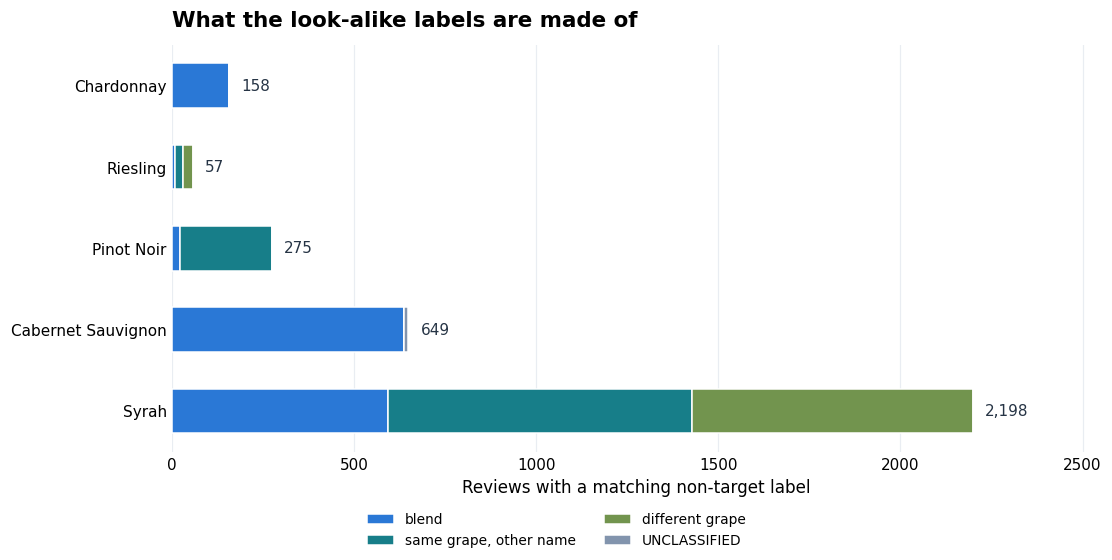

In [13]:
# Figure: look-alike label categories in the original dataset.
from IPython.display import display, Markdown

if DATA_STAGE != "raw":
    print("Skipped: this figure requires the original file (raw mode).")

else:
    if "kind_summary" not in globals():
        raise NameError(
            "Run the look-alike label classification cell first: "
            "it creates kind_summary."
        )

    kind_order = [
        "blend",
        "same grape, other name",
        "different grape",
        "UNCLASSIFIED",
    ]

    # Local palette: no additional colour settings are needed.
    kind_colors = {
        "blend": "#2A78D6",
        "same grape, other name": "#177E89",
        "different grape": "#72944E",
        "UNCLASSIFIED": "#8294AD",
    }

    kinds_present = [
        kind for kind in kind_order
        if kind in kind_summary.columns
    ]

    stack = (
        kind_summary
        .reindex(index=CLASSES, columns=kinds_present)
        .fillna(0)
        .astype(float)
    )

    if stack.empty or stack.to_numpy().sum() == 0:
        print("No look-alike label reviews to plot.")

    else:
        fig, ax = plt.subplots(
            figsize=(10, 5),
            layout="constrained",
            facecolor="white",
        )

        left = np.zeros(len(CLASSES))

        for kind in kinds_present:
            values = stack[kind].to_numpy()

            ax.barh(
                CLASSES,
                values,
                left=left,
                height=0.55,
                color=kind_colors[kind],
                edgecolor="white",
                linewidth=1,
                label=kind,
                zorder=3,
            )

            left += values

        largest_total = float(left.max())
        label_padding = max(largest_total * 0.015, 1)

        for position, total in enumerate(left):
            ax.text(
                total + label_padding,
                position,
                f"{int(total):,}",
                va="center",
                fontsize=10,
                color="#263445",
            )

        ax.invert_yaxis()
        ax.set_xlim(0, largest_total * 1.16)
        ax.set_xlabel("Reviews with a matching non-target label")
        ax.set_title(
            "What the look-alike labels are made of",
            loc="left",
            fontsize=14,
            fontweight="bold",
            pad=12,
        )

        ax.set_axisbelow(True)
        ax.grid(axis="x", color="#E9EDF2", linewidth=0.8)
        ax.tick_params(axis="both", length=0)

        for spine in ax.spines.values():
            spine.set_visible(False)

        fig.legend(
            handles=ax.get_legend_handles_labels()[0],
            labels=ax.get_legend_handles_labels()[1],
            loc="outside lower center",
            ncol=2,
            frameon=False,
            fontsize=9,
        )

        FIGURES_DIR.mkdir(parents=True, exist_ok=True)

        fig.savefig(
            FIGURES_DIR / "f1c_look_alike_kinds.png",
            dpi=200,
            bbox_inches="tight",
            facecolor="white",
        )

        plt.show()

        # Compare alternative-name counts with exact-label counts.
        same_name_counts = stack.get(
            "same grape, other name",
            pd.Series(0.0, index=CLASSES),
        )

        alternative_reviews = int(same_name_counts.sum())
        exact_reviews = int(
            TARGET_COUNTS.reindex(CLASSES, fill_value=0).sum()
        )

        if exact_reviews <= 0:
            raise ValueError("Exact-label review count must be positive.")

        relative_size = 100 * alternative_reviews / exact_reviews

#### What the look-alike label chart tells us
The interpretation below uses the chart together with the
`kind_summary` and `merge_check` tables above. Relative percentages
are calculated against the corresponding exact-label counts.

**The excluded labels have different meanings.** Syrah has the largest
number of matching non-target records: 2,198, comprising 592 records
classified as blends, 836 under mapped alternative names and 770
classified as a different grape. These categories should not all be
merged into the Syrah class. The figure summarizes the documented
classification rules, not an exhaustive botanical audit.

**The overall percentage hides a class-specific difference.** Mapped
alternative names account for 1,111 records, equivalent to 2.5% of
the 43,828 exact-label records. However, their relative size is 20.2%
for Syrah, compared with 1.9% for Pinot Noir and 0.4% for Riesling.
Therefore, excluding alternative names affects the scope of some
classes more than others. The aggregate 2.5% should not be interpreted
as an equally small effect for every class.

**Our decision.** We retain exact target labels only. Merging names
is not needed to reach the planned cap before cleaning, and changing
the label policy would change the defined task. This choice may also
change which origins and styles are represented; the chart does not
measure those distribution changes or their effect on model quality.

**Limits.** A blend mentioning two target grapes can appear under both
bars, so totals across grapes are not necessarily additive. Three
distinct labels remain unclassified and excluded under the exact-label
rule. Label selection is separate from text masking: verified
alternative names of target grapes still belong in the L1 dictionary,
even when records carrying those labels are excluded.

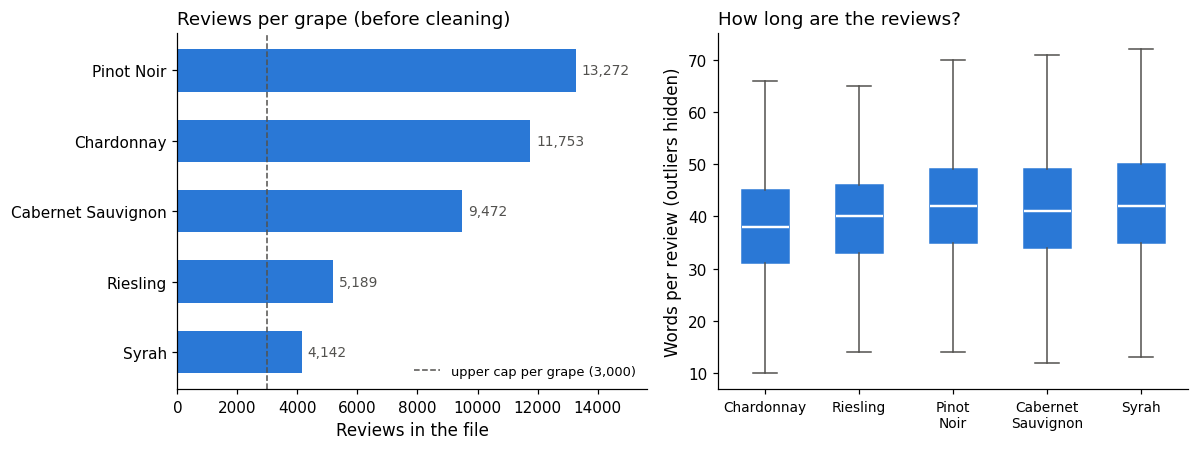

                      count  mean   std   min   25%   50%   75%    max
variety                                                               
Chardonnay          11753.0  38.3  10.9   3.0  31.0  38.0  45.0  104.0
Riesling             5189.0  41.0  11.9   6.0  33.0  40.0  46.0  125.0
Pinot Noir          13272.0  42.5  11.5   6.0  35.0  42.0  49.0  116.0
Cabernet Sauvignon   9472.0  41.9  12.6   8.0  34.0  41.0  49.0  135.0
Syrah                4142.0  42.7  12.0  10.0  35.0  42.0  50.0  115.0


In [14]:
# Figure: review counts and lengths in the original data.
if DATA_STAGE == "raw":
    fig, (ax_count, ax_len) = plt.subplots(
        1, 2, figsize=(11, 4.2)
    )

    order = target_overview.sort_values("n_reviews")

    bars = ax_count.barh(
        order["variety"],
        order["n_reviews"],
        color=PLOT_COLOR,
        height=0.6,
    )

    ax_count.bar_label(
        bars,
        labels=[f"{n:,}" for n in order["n_reviews"]],
        padding=4,
        color=INK,
        fontsize=9,
    )

    x_max = max(order["n_reviews"].max(), SAMPLE_CAP) * 1.18
    ax_count.set_xlim(0, x_max)

    ax_count.axvline(
        SAMPLE_CAP,
        color=INK,
        linestyle="--",
        linewidth=1,
        label=f"upper cap per grape ({SAMPLE_CAP:,})",
    )

    ax_count.legend(
        frameon=False,
        loc="lower right",
        fontsize=8.5,
    )
    ax_count.set_xlabel("Reviews in the file")
    ax_count.set_title(
        "Reviews per grape (before cleaning)",
        loc="left",
    )

    length_data = [
        five.loc[five["variety"].eq(grape), "n_words"]
        for grape in CLASSES
    ]

    box = ax_len.boxplot(
        length_data,
        showfliers=False,
        patch_artist=True,
        medianprops={
            "color": "white",
            "linewidth": 1.6,
        },
    )

    for patch in box["boxes"]:
        patch.set(
            facecolor=PLOT_COLOR,
            edgecolor=PLOT_COLOR,
        )

    for line in box["whiskers"] + box["caps"]:
        line.set(color=INK, linewidth=1)

    ax_len.set_xticks(range(1, len(CLASSES) + 1))
    ax_len.set_xticklabels(
        [grape.replace(" ", "\n") for grape in CLASSES],
        fontsize=9,
    )
    ax_len.set_ylabel("Words per review (outliers hidden)")
    ax_len.set_title("How long are the reviews?", loc="left")

    fig.tight_layout()

    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        FIGURES_DIR / "f1a_first_look_raw.png",
        bbox_inches="tight",
    )

    plt.show()

    print(
        five.groupby("variety")["n_words"]
        .describe()
        .loc[CLASSES]
        .round(1)
        .to_string()
    )

else:
    print("Original-data exploration skipped in sample mode.")

**What do the reviews actually look like?**

One random review per grape, selected with our fixed seed.
Labels are shown for interpretation. These examples illustrate
the original texts before cleaning and masking.

In [15]:
if DATA_STAGE == "raw":
    examples = (
        five.groupby("variety", group_keys=False)
        .sample(n=1, random_state=SEED)
        .set_index("variety")
        .loc[CLASSES]
    )

    for grape, row in examples.iterrows():
        print(f"[{grape}]")
        print(
            textwrap.fill(
                str(row["description"]),
                width=100,
            )
        )
        print()

else:
    print("Original-data exploration skipped in sample mode.")

[Chardonnay]
For basic Chardonnay, this fits the bill as a good quaffer. Pithy citrus aromas lead to a zesty,
citrusy palate with flavors of green fruits, lemongrass and green herbs. It's lasting on the finish
and a touch ripe.

[Riesling]
Subtle hints of cereal and grain permeate throughout this medium-sweet Riesling, lending a savory
tone to honeyed grapefruit and apple flavors. While lacking great refinement, it offers fruit-
forward refreshment for casual settings. Drink now.

[Pinot Noir]
So delicious and easy to drink, it's complexities are almost unappreciated. Lush, ripe raspberry,
cherry and cola flavors flatter the palate, finished with smoky toast and exotic spices. Extra
points for crisp acidity and lovely tannins.

[Cabernet Sauvignon]
Soft with cranberry and red currant accents, this fairly priced wine is subtle in tannin and oak,
with a core of succulent black cherry and clove flavor. Approachable and round on the palate, it's a
good choice for big gatherings.

[Syrah]
D

**A quick peek at why masking matters.**

We count reviews containing their target variety's exact name,
using word boundaries and ignoring capitalization.

This check misses spelling variants and abbreviations. A matched
name is a potential clue, but it may refer to a comparison or blend
rather than directly identify the reviewed wine. These percentages
are pattern-match rates, not model accuracy.

In [16]:
if DATA_STAGE == "raw":

    def names_its_grape(texts, grape):
        pattern = re.compile(
            r"\b" + re.escape(grape) + r"\b",
            flags=re.IGNORECASE,
        )

        return (
            texts.fillna("")
            .astype(str)
            .apply(lambda text: bool(pattern.search(text)))
        )

    peek_rows = []

    for grape in CLASSES:
        texts = five.loc[
            five["variety"].eq(grape),
            "description",
        ]

        hit = names_its_grape(texts, grape)

        peek_rows.append({
            "variety": grape,
            "reviews": len(texts),
            "name_the_grape": int(hit.sum()),
            "share": round(100 * float(hit.mean()), 1),
        })

    name_peek = pd.DataFrame(peek_rows)

    display(
        name_peek.assign(
            share=name_peek["share"].map(
                lambda value: f"{value:.1f}%"
            )
        )
    )

else:
    print("Original-data exploration skipped in sample mode.")

,variety,reviews,name_the_grape,share
0,Chardonnay,11753,3215,27.4%
1,Riesling,5189,2155,41.5%
2,Pinot Noir,13272,2192,16.5%
3,Cabernet Sauvignon,9472,682,7.2%
4,Syrah,4142,1543,37.3%


**Do short forms change the picture?** The table above counts only the exact grape name. Reviewers also use short forms (*Cab*, *Chard*) or a second name (*Shiraz*). Here we count those too. The short forms are a rough hand-picked list, not our final L1 word list, but they show how much the first count may miss.

In [17]:
if DATA_STAGE == "raw":
    SHORT_FORMS = {
        "Chardonnay": r"\bchardonnay\b|\bchard\b",
        "Riesling": r"\briesling\b",
        "Pinot Noir": r"\bpinot noir\b|\bpinot\b",
        "Cabernet Sauvignon": (
            r"\bcabernet sauvignon\b|\bcabernet\b|\bcab\b"
        ),
        "Syrah": r"\bsyrah\b|\bshiraz\b",
    }

    rows = []

    for grape in CLASSES:
        texts = (
            five.loc[
                five["variety"].eq(grape),
                "description",
            ]
            .fillna("")
            .astype(str)
        )

        exact = texts.str.contains(
            r"\b" + re.escape(grape) + r"\b",
            case=False,
            regex=True,
        )

        broad = texts.str.contains(
            SHORT_FORMS[grape],
            case=False,
            regex=True,
        )

        rows.append({
            "variety": grape,
            "exact_name_%": round(100 * exact.mean(), 1),
            "with_short_forms_%": round(100 * broad.mean(), 1),
        })

    short_form_check = pd.DataFrame(rows)

    short_form_check["added_by_short_forms"] = (
        short_form_check["with_short_forms_%"]
        - short_form_check["exact_name_%"]
    ).round(1)

    display(short_form_check)

else:
    print("Original-data exploration skipped in sample mode.")

,variety,exact_name_%,with_short_forms_%,added_by_short_forms
0,Chardonnay,27.4,30.3,2.9
1,Riesling,41.5,41.5,0.0
2,Pinot Noir,16.5,28.1,11.6
3,Cabernet Sauvignon,7.2,40.5,33.3
4,Syrah,37.3,37.4,0.1


**Do broader patterns find more name mentions?**

For each variety, the bars compare exact-name matches with matches
from a broader pattern that includes selected short forms or aliases.

The largest increase is for Cabernet Sauvignon (7.2% to 40.5%),
followed by Pinot Noir (16.5% to 28.1%). These are exploratory
pattern-match rates, not model accuracy or verified label disclosures.
Broad terms such as `Pinot` and `Cabernet` can be ambiguous.

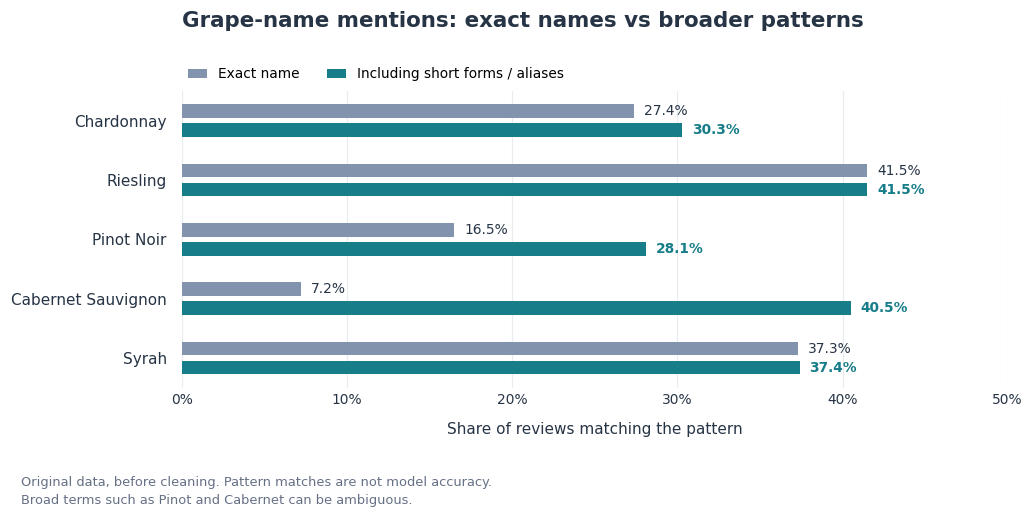

In [18]:
# Compare exact names with broader exploratory patterns.
if DATA_STAGE == "raw":
    plot_df = (
        short_form_check
        .set_index("variety")
        .loc[CLASSES]
    )

    exact = plot_df["exact_name_%"].to_numpy()
    broad = plot_df["with_short_forms_%"].to_numpy()
    y = np.arange(len(plot_df))

    EXACT_COLOR = "#8294AD"
    BROAD_COLOR = "#177E89"
    TEXT_COLOR = "#263445"

    fig, ax = plt.subplots(
        figsize=(9.5, 4.8),
        facecolor="white",
    )
    ax.set_facecolor("white")

    bar_height = 0.23
    offset = 0.16

    ax.barh(
        y - offset,
        exact,
        height=bar_height,
        color=EXACT_COLOR,
        label="Exact name",
        zorder=3,
    )

    ax.barh(
        y + offset,
        broad,
        height=bar_height,
        color=BROAD_COLOR,
        label="Including short forms / aliases",
        zorder=3,
    )

    for position, exact_rate, broad_rate in zip(y, exact, broad):
        ax.text(
            exact_rate + 0.6,
            position - offset,
            f"{exact_rate:.1f}%",
            va="center",
            fontsize=9,
            color=TEXT_COLOR,
        )

        ax.text(
            broad_rate + 0.6,
            position + offset,
            f"{broad_rate:.1f}%",
            va="center",
            fontsize=9,
            color=BROAD_COLOR,
            weight="bold",
        )

    ax.set_yticks(y)
    ax.set_yticklabels(
        plot_df.index,
        fontsize=10,
        color=TEXT_COLOR,
    )
    ax.set_ylim(len(plot_df) - 0.5, -0.5)

    ax.set_xlim(0, 50)

    ticks = np.arange(0, 51, 10)
    ax.set_xticks(ticks)
    ax.set_xticklabels(
        [f"{value}%" for value in ticks],
        fontsize=9,
    )

    ax.set_xlabel(
        "Share of reviews matching the pattern",
        fontsize=10,
        color=TEXT_COLOR,
        labelpad=10,
    )

    ax.set_title(
        "Grape-name mentions: exact names vs broader patterns",
        loc="left",
        fontsize=14,
        weight="bold",
        color=TEXT_COLOR,
        pad=42,
    )

    ax.legend(
        loc="lower left",
        bbox_to_anchor=(0, 1.015),
        ncol=2,
        frameon=False,
        fontsize=9,
        borderaxespad=0,
        handlelength=1.4,
        columnspacing=2,
    )

    ax.set_axisbelow(True)
    ax.grid(
        axis="x",
        color="#E9EDF2",
        linewidth=0.8,
    )
    ax.tick_params(
        axis="both",
        length=0,
        labelcolor=TEXT_COLOR,
    )
    ax.tick_params(axis="y", pad=10)

    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.tight_layout(rect=(0, 0.13, 1, 1))

    fig.text(
        0.025,
        0.035,
        "Original data, before cleaning. "
        "Pattern matches are not model accuracy.\n"
        "Broad terms such as Pinot and Cabernet can be ambiguous.",
        fontsize=8.5,
        color="#667085",
        linespacing=1.5,
    )

    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        FIGURES_DIR / "f1b_name_cues_raw.png",
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

else:
    print("Original-data exploration skipped in sample mode.")

### 3.4 What we noticed in the original file

These observations document the original-data preparation run,
before cleaning or balancing. They are not recalculated in
`sample` mode and are not model-performance estimates.

**Size, missing values and class counts.** The file contains **129,971 reviews and 14 columns**, including the exported index `Unnamed: 0`. The five exact target labels account for **43,828 reviews**:

| Variety | Reviews before cleaning | Distinct normalized winery names | Mean words per review |
|---|---:|---:|---:|
| Chardonnay | 11,753 | 3,380 | 38.3 |
| Riesling | 5,189 | 1,041 | 41.0 |
| Pinot Noir | 13,272 | 2,658 | 42.5 |
| Cabernet Sauvignon | 9,472 | 2,918 | 41.9 |
| Syrah | 4,142 | 1,430 | 42.7 |

Every exact-label class currently exceeds the cap of 3,000, but this does not yet guarantee 3,000 usable reviews per class: missing or blank required fields, conflicting labels and duplicates still need to be checked during cleaning. The largest class is about 3.2 times the smallest, so this selected subset is not balanced yet.

The missing-value table reports **no pandas-detected missing values in `description` or `winery`**, and **one in `variety`** across the full file. This does not replace checks for blank or whitespace-only strings. Missing metadata include 8,996 prices, 21,247 `region_1` values, 79,460 `region_2` values and 26,244 taster names. Missing optional metadata will not by itself cause a review to be discarded from the main text experiment.

**Many winery names, but no validated folds yet.** The per-class counts range from 1,041 to 3,380 distinct winery names after case and whitespace normalization. Average reviews per winery within a class range from 2.9 to 5.0. These counts make grouped validation worth pursuing, but they do not establish that every future split will contain all five classes. We will check class coverage and group separation explicitly. The same winery may occur in several classes, so the per-class winery counts must not be added to obtain a total. Name normalization also does not guarantee that all aliases of a real winery have been resolved.

**Review lengths are broadly similar.** Mean lengths range from 38.3 to 42.7 whitespace-separated words, and medians range from 38 to 42. Chardonnay reviews are somewhat shorter on average. This is descriptive evidence about text length, not evidence that length predicts the grape or explains future errors. The boxplot hides outlier points for readability; no reviews have been removed because of their length.

**Potential name cues are common, and abbreviations matter.** The two checks above give:

| Variety | Exact name matched | Broader pattern matched | Increase (percentage points) |
|---|---:|---:|---:|
| Chardonnay | 27.4% | 30.3% | 2.9 |
| Riesling | 41.5% | 41.5% | 0.0 |
| Pinot Noir | 16.5% | 28.1% | 11.6 |
| Cabernet Sauvignon | 7.2% | 40.5% | 33.3 |
| Syrah | 37.3% | 37.4% | 0.1 |

The largest increase is for Cabernet Sauvignon, followed by Pinot Noir. This motivates checking spelling variants and abbreviations when preparing L1. However, broad terms such as `Pinot` and `Cabernet` are not uniquely specific to the target variety. Even an exact name can occur in a comparison or a discussion of a blend. These are pattern-match rates, not verified rates of reviews that reveal their own label, and not expected model accuracy. The exploratory patterns are not the final masking dictionary. The zero increase for Riesling is expected because its exact and broad patterns are identical here.

### Label choices and their limits

- **We retain exact target labels only.** The target labels are Chardonnay, Riesling, Pinot Noir, Cabernet Sauvignon and Syrah. We do not merge alternative labels, and we exclude separately labeled blends. This defines a restricted task; it does not establish that every retained wine is made entirely from a single grape.
- **Alternative names are not negligible for every class.** Under the manual mapping above, merging same-grape names would add 22 Riesling reviews (0.4%), 253 Pinot Noir reviews (1.9%) and 836 Syrah reviews (20.2%). There are no mapped additions for Chardonnay or Cabernet Sauvignon in this diagnostic. The raw exact-label counts already exceed the cap, so merging is not needed merely to reach 3,000 before cleaning. However, excluding names such as Shiraz can change which origins and styles are represented; it is a scope choice, not a guarantee of an equivalent sample.
- **The label audit is not complete.** The current code leaves three distinct labels unclassified: `Chardonnay Weissburgunder` (2 reviews), `Cabernet` (11) and `Cabernet Sauvignon Grenache` (2). They are excluded by the exact-label rule regardless of their eventual classification. We must document their treatment before presenting the auxiliary classification table as complete. In particular, the hyphen-based rule does not identify every possible blend label. Look-alike tables are pattern-based diagnostics, not an exhaustive catalogue of grape synonyms, and their per-grape totals can overlap.
- **Label filtering and text masking are separate decisions.** Excluding reviews labeled Shiraz does not justify leaving the word Shiraz in a Syrah review at L1. Verified alternative names of the five target grapes belong in the L1 dictionary; verified names of other grapes belong in L2. Ambiguous short forms need an explicit policy. The same frozen masking rules must be applied to every review without consulting its true class.
- **Our conclusions will concern a balanced, exact-label subset.** We will not claim performance for all wine varieties, all alternative labels or naturally occurring class frequencies. We rely on the dataset's labels rather than independently verifying each bottle's composition.


### 3.5 Where we are, and what is next

In `raw` mode, the preceding cells inspect the original CSV.
Section 4 then cleans the data and creates or verifies the shared
sample.

In `sample` mode, the preceding loader verifies the frozen sample's
checksum. Original-data exploration is skipped, and Section 4.1
validates the sample without recreating it.

No model training or predictive evaluation has been performed yet.

**Input verification and the remaining label-audit limitation**

The selected input file's SHA-256 matches its configured reference
(`matched_reference`).

The auxiliary label audit still reports three unclassified labels:
`Chardonnay Weissburgunder`, `Cabernet`, and
`Cabernet Sauvignon Grenache`. They remain excluded under our
exact-label rule. Their treatment must be documented before
presenting the auxiliary audit as complete.

Next is **section 4: cleaning and the shared sample**, using the following order:

1. **Preserve provenance before filtering.** Start from a copy of the raw table and assign `source_row` and a stable `row_id` from the original record position. Remove the exported `Unnamed: 0` column deliberately; do not use it as a predictive feature.
2. **Apply the exact-label rule.** Retain the five agreed target labels and record the number of rows excluded. Rows with a missing target do not meet this rule.
3. **Check required fields.** Exclude missing or blank descriptions and winery names, recording removals at each step. Do not drop records merely because optional metadata are missing.
4. **Resolve duplicate descriptions.** Use a documented normalization for comparison. Among the retained target classes, remove all records whose normalized description has conflicting target labels. For the remaining repeated descriptions with the same label, keep the first record in original order. This detects duplicates under the chosen normalization, not every near-duplicate text.
5. **Create the balanced sample.** Select `min(SAMPLE_CAP, smallest cleaned class size)` records per class with the fixed seed (`SEED = 42`). Confirm class counts, nonempty required fields and unique IDs and normalized descriptions.
6. **Save the shared inputs and provenance.** Write `data/wine_sample.csv`, a hash-only `data/wine_sample.sha256`, the cleaning-flow table and a data README with source, version, attribution, license, selection rules and final counts. Verify the saved CSV before freezing it for the team.

If every class still has at least 3,000 records after cleaning, the sample will contain 15,000 reviews. Otherwise, all five classes will use the smaller available count. We do not report a final sample size until this step has actually run.

After the sample is frozen, participant 3 creates and checks the shared winery-grouped DEV/MAIN split and folds. Participant 2 can continue testing masking on synthetic examples in parallel, then inspect DEV examples once the split exists. Participant 1 prepares the cleaned-sample EDA. Masking dictionaries and tuning choices may use external sources and DEV, but must be frozen before MAIN evaluation; MAIN texts must not be inspected to expand the masking rules.



## 4. Cleaning and the shared sample *(course step 2)*

The original Wine Reviews dataset contains missing values, repeated descriptions, and many grape varieties outside the scope of our study. Before creating the shared dataset, we apply a fixed and reproducible cleaning procedure.

Our goal is to obtain a balanced sample of five grape varieties while preserving the original review text and the metadata required for grouped validation and later analysis.

The cleaning procedure follows these principles:

1. Preserve the original record position for traceability.
2. Keep only the five agreed target varieties.
3. Remove records with missing or blank required fields.
4. Identify conflicting labels and duplicate descriptions.
5. Keep one record per normalized description.
6. Select an equal number of reviews per variety using the fixed random seed.
7. Normalize winery names for grouped validation.
8. Save the sample, its SHA-256 checksum, and a detailed cleaning report.

The original dataset is never modified. The resulting shared sample is saved separately and will be used by all three models.

The sample is generated explicitly during initial preparation. Regular notebook runs will load and validate the frozen sample without recreating it.



### 4.1 Cleaning configuration and required fields

We reuse the project settings defined in Section 2 rather than introducing separate constants.

The required columns are `description`, `variety`, and `winery`. Records with missing or blank values in these fields cannot be used in the main study.

Optional metadata, including geographical information and reviewer names, are preserved when available. Missing optional values are not grounds for removing a review.

We also preserve the original row position as `source_row` and use it as the stable `row_id`. Neither identifier will be used as a predictive feature.

The cleaning procedure operates only on the original Kaggle dataset.


In [19]:
# Section 4.1 — Preparation or frozen-sample initialization

REQUIRED_FIELDS = ["description", "variety", "winery"]

if DATA_STAGE not in {"raw", "sample"}:
    raise ValueError("DATA_STAGE must be 'raw' or 'sample'.")

PREPARE_SAMPLE = DATA_STAGE == "raw"
PREPARATION_DIR = RESULTS_DIR / "data_preparation"

if PREPARE_SAMPLE:
    # Validate the original input before preparing a new sample.
    if INPUT_PATH.name != RAW_FILENAME:
        raise ValueError("The original Kaggle CSV is required.")

    missing = set(REQUIRED_FIELDS) - set(input_df.columns)
    if missing:
        raise ValueError(f"Required columns are missing: {sorted(missing)}")

    reserved_columns = {
        "source_row", "row_id", "description_key", "winery_group"
    }
    unexpected = reserved_columns & set(input_df.columns)

    if unexpected:
        raise ValueError(
            f"The raw dataset contains reserved columns: {sorted(unexpected)}"
        )

    PREPARATION_DIR.mkdir(parents=True, exist_ok=True)

    print("Mode: raw — sample preparation")
    print("Source:", INPUT_PATH)
    print("Original rows:", len(input_df))
    print("Target varieties:", CLASSES)
    print("Maximum reviews per variety:", SAMPLE_CAP)
    print("Random seed:", SEED)
    print("Output:", SAMPLE_PATH)

else:
    # Section 3 must already have loaded and hash-checked the sample.
    if INPUT_PATH.resolve() != SAMPLE_PATH.resolve():
        raise ValueError("Sample mode requires the configured sample CSV.")

    required_sample_columns = set(REQUIRED_FIELDS) | {
        "row_id", "source_row", "winery_group"
    }
    missing = required_sample_columns - set(input_df.columns)

    if missing:
        raise ValueError(f"Sample columns are missing: {sorted(missing)}")

    reference_hash = (
        SAMPLE_HASH_PATH.read_text(encoding="utf-8").strip().lower()
    )
    sample_hash = sha256_file(SAMPLE_PATH)

    if (
        re.fullmatch(r"[0-9a-f]{64}", reference_hash) is None
        or sample_hash != reference_hash
        or sample_hash != INPUT_SHA256
    ):
        raise ValueError(
            "Sample verification failed. Rerun Section 3 "
            "with the matching CSV and checksum."
        )

    sample_df = input_df.copy(deep=True)

    for column in REQUIRED_FIELDS + ["winery_group"]:
        values = sample_df[column]
        if values.isna().any() or values.astype(str).str.strip().eq("").any():
            raise ValueError(f"Missing or blank values in '{column}'.")

    for column in ["row_id", "source_row"]:
        values = sample_df[column]
        if (
            values.isna().any()
            or not values.is_unique
            or not pd.api.types.is_integer_dtype(values.dtype)
            or values.lt(0).any()
        ):
            raise ValueError(
                f"'{column}' must contain unique nonnegative integers."
            )

    if not sample_df["row_id"].eq(sample_df["source_row"]).all():
        raise ValueError("row_id and source_row do not match.")

    counts = (
        sample_df["variety"]
        .value_counts()
        .reindex(CLASSES, fill_value=0)
    )

    if (
        not sample_df["variety"].isin(CLASSES).all()
        or counts.eq(0).any()
        or counts.nunique() != 1
        or counts.max() > SAMPLE_CAP
    ):
        raise ValueError("The sample does not satisfy the agreed class balance.")

    description_keys = (
        sample_df["description"].astype(str)
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    if not description_keys.is_unique:
        raise ValueError("The sample contains repeated normalized descriptions.")

    expected_groups = (
        sample_df["winery"].astype(str)
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    if not expected_groups.eq(sample_df["winery_group"]).all():
        raise ValueError("winery_group does not match the normalization rule.")

    n_per_class = int(counts.iloc[0])
    saved_sample = sample_df.copy(deep=True)

    print("Mode: sample — frozen data loaded and validated")
    print("Rows:", len(sample_df))
    print("Reviews per variety:", n_per_class)
    print("Unique winery groups:", sample_df["winery_group"].nunique())
    print("SHA-256:", sample_hash)
    print("Preparation is skipped; use sample_df for subsequent work.")

Mode: raw — sample preparation
Source: /content/winemag-data-130k-v2.csv
Original rows: 129971
Target varieties: ['Chardonnay', 'Riesling', 'Pinot Noir', 'Cabernet Sauvignon', 'Syrah']
Maximum reviews per variety: 3000
Random seed: 42
Output: /content/data/wine_sample.csv



### 4.2 Preserving provenance and selecting target varieties

Each review receives two identifiers before filtering:

- `source_row` records its original zero-based position in the source CSV.
- `row_id` is a stable identifier used to connect the sample with later predictions and error analyses.

The exported `Unnamed: 0` column is removed explicitly because it is not a meaningful feature.

We then retain only reviews whose `variety` exactly matches one of the five target classes: Chardonnay, Riesling, Pinot Noir, Cabernet Sauvignon, or Syrah.

Other labels, including Shiraz, blends, and alternative names, are excluded. We do not silently merge them into the target classes.

The number of excluded records is recorded in the cleaning log.


In [20]:
# Section 4.2 — Preserve provenance and select classes

if PREPARE_SAMPLE:
    cleaned_df = input_df.copy()

    cleaning_log = []

    def log_cleaning_step(step, before, after):
        cleaning_log.append({
            "step": step,
            "rows_before": int(before),
            "rows_after": int(after),
            "rows_removed": int(before - after),
        })

    # Preserve original positions before any filtering.
    cleaned_df["source_row"] = np.arange(
        len(cleaned_df), dtype=np.int64
    )
    cleaned_df["row_id"] = cleaned_df["source_row"]

    # Remove only exported unnamed index columns.
    unnamed_columns = [
        col for col in cleaned_df.columns
        if re.fullmatch(r"Unnamed: \d+", str(col))
    ]

    cleaned_df = cleaned_df.drop(columns=unnamed_columns)

    # Keep only the five agreed target varieties.
    before = len(cleaned_df)

    cleaned_df = cleaned_df.loc[
        cleaned_df["variety"].isin(CLASSES)
    ].copy()

    log_cleaning_step(
        "Exact target variety selection",
        before,
        len(cleaned_df),
    )

    print("Removed exported columns:", unnamed_columns)
    print("Rows retained:", len(cleaned_df))
    print("Rows excluded:", before - len(cleaned_df))

    display(
        cleaned_df["variety"]
        .value_counts()
        .reindex(CLASSES, fill_value=0)
        .rename("reviews")
        .to_frame()
    )

else:
    print("Section 4.2 skipped: using the validated frozen sample.")

Removed exported columns: ['Unnamed: 0']
Rows retained: 43828
Rows excluded: 86143


,reviews
variety,
Chardonnay,11753
Riesling,5189
Pinot Noir,13272
Cabernet Sauvignon,9472
Syrah,4142



### 4.3 Removing missing and blank required fields

A review is usable only when its description, variety, and winery are present and nonempty.

We first remove missing values in the required columns. We then strip leading and trailing whitespace and remove records containing only whitespace.

We do not remove records because of missing prices, ratings, regions, or reviewer names. These fields are not required for the primary text classification task.

Removal counts are recorded separately for missing values and blank strings.


In [21]:
# Section 4.3 — Remove missing and blank required values

if PREPARE_SAMPLE:
  before = len(cleaned_df)

  cleaned_df = cleaned_df.dropna(
      subset=REQUIRED_FIELDS
  ).copy()

  log_cleaning_step(
      "Missing required values",
      before,
      len(cleaned_df)
  )

  # Convert required values to strings and strip outer spaces.
  for column in REQUIRED_FIELDS:
      cleaned_df[column] = (
          cleaned_df[column]
          .astype(str)
          .str.strip()
      )

  before = len(cleaned_df)

  blank_mask = cleaned_df[REQUIRED_FIELDS].apply(
      lambda column: column.str.strip().eq("")
  ).any(axis=1)

  cleaned_df = cleaned_df.loc[~blank_mask].copy()

  log_cleaning_step(
      "Blank required values",
      before,
      len(cleaned_df)
  )

  assert not cleaned_df[REQUIRED_FIELDS].isna().any().any()

  assert not cleaned_df[REQUIRED_FIELDS].apply(
      lambda column: column.str.strip().eq("")
  ).any().any()

  print("Rows after required-field cleaning:", len(cleaned_df))
  display(pd.DataFrame(cleaning_log))

else:
    print("Skipped: using the validated frozen sample.")

Rows after required-field cleaning: 43828


,step,rows_before,rows_after,rows_removed
0,Exact target variety selection,129971,43828,86143
1,Missing required values,43828,43828,0
2,Blank required values,43828,43828,0



### 4.4 Detecting duplicate descriptions and conflicting labels

Repeated reviews can distort model evaluation if identical texts appear in different data partitions.

We create a normalized description key for duplicate detection by applying Unicode-aware case folding, collapsing repeated whitespace, and removing leading and trailing whitespace.

Two cases are handled separately:

1. **Conflicting labels:** if the same normalized description is associated with multiple target varieties, all records with that description are removed.
2. **Repeated descriptions:** if the normalized description has a consistent target label, only the first occurrence in the original source order is retained.

This procedure removes duplicates under the documented normalization rule. It does not guarantee the removal of paraphrased or near-duplicate reviews.

Review wording is preserved apart from trimming leading and
trailing whitespace.


In [22]:
# Section 4.4 — Normalize descriptions for duplicate detection

if PREPARE_SAMPLE:

  cleaned_df["description_key"] = (
      cleaned_df["description"]
      .str.casefold()
      .str.replace(r"\s+", " ", regex=True)
      .str.strip()
  )

  # Count distinct labels for every normalized description.
  label_counts = cleaned_df.groupby(
      "description_key"
  )["variety"].nunique()

  conflicting_keys = label_counts[
      label_counts > 1
  ].index

  before = len(cleaned_df)

  conflict_mask = cleaned_df[
      "description_key"
  ].isin(conflicting_keys)

  conflicting_rows = int(conflict_mask.sum())
  conflicting_descriptions = len(conflicting_keys)

  cleaned_df = cleaned_df.loc[
      ~conflict_mask
  ].copy()

  log_cleaning_step(
      "Conflicting description labels",
      before,
      len(cleaned_df)
  )

  # Preserve the first original occurrence.
  cleaned_df = cleaned_df.sort_values(
      "source_row",
      kind="stable"
  )

  before = len(cleaned_df)

  cleaned_df = cleaned_df.drop_duplicates(
      subset="description_key",
      keep="first"
  ).copy()

  log_cleaning_step(
      "Repeated descriptions",
      before,
      len(cleaned_df)
  )

  assert cleaned_df["description_key"].is_unique

  print("Conflicting descriptions:", conflicting_descriptions)
  print("Rows removed due to conflicts:", conflicting_rows)
  print("Rows after duplicate removal:", len(cleaned_df))

  display(pd.DataFrame(cleaning_log))

else:
    print("Skipped: using the validated frozen sample.")

Conflicting descriptions: 0
Rows removed due to conflicts: 0
Rows after duplicate removal: 40581


,step,rows_before,rows_after,rows_removed
0,Exact target variety selection,129971,43828,86143
1,Missing required values,43828,43828,0
2,Blank required values,43828,43828,0
3,Conflicting description labels,43828,43828,0
4,Repeated descriptions,43828,40581,3247



### 4.5 Creating a balanced sample

The cleaned dataset may still contain substantially different numbers of reviews for different grape varieties.

To make the comparison consistent, we select the same number of reviews from each of the five classes.

The sample size per class is defined as:

\[
n = \min(3000, \min_c N_c),
\]

where \(N_c\) is the number of available cleaned reviews for class \(c\).

We use the shared project seed (`SEED = 42`) for reproducible random sampling.

After selecting the records, we shuffle the combined sample using the same seed. The stable identifiers are preserved.

Balancing is performed only after removing missing values, conflicting labels, and duplicate descriptions.


In [23]:
# Section 4.5 — Balanced sampling

if PREPARE_SAMPLE:

  clean_class_counts = (
      cleaned_df["variety"]
      .value_counts()
      .reindex(CLASSES, fill_value=0)
  )

  if (clean_class_counts == 0).any():
      raise ValueError(
          "At least one target variety has no cleaned reviews."
      )

  n_per_class = min(
      SAMPLE_CAP,
      int(clean_class_counts.min())
  )

  sample_parts = []

  for grape in CLASSES:
      class_rows = cleaned_df[
          cleaned_df["variety"] == grape
      ]

      selected = class_rows.sample(
          n=n_per_class,
          random_state=SEED
      )

      sample_parts.append(selected)

  sample_df = pd.concat(
      sample_parts,
      ignore_index=True
  )

  # Shuffle the combined sample.
  sample_df = sample_df.sample(
      frac=1,
      random_state=SEED
  ).reset_index(drop=True)

  print("Reviews per class:", n_per_class)
  print("Total sample size:", len(sample_df))

  display(
      sample_df["variety"]
      .value_counts()
      .reindex(CLASSES, fill_value=0)
      .rename("sample_count")
      .to_frame()
  )

  assert len(sample_df) == 5 * n_per_class
  assert sample_df["row_id"].is_unique
  assert sample_df["description_key"].is_unique

else:
    print("Skipped: using the validated frozen sample.")

Reviews per class: 3000
Total sample size: 15000


,sample_count
variety,
Chardonnay,3000
Riesling,3000
Pinot Noir,3000
Cabernet Sauvignon,3000
Syrah,3000



### 4.6 Winery normalization and integrity checks

The primary evaluation will use winery-grouped cross-validation. Reviews associated with the same normalized winery must remain together within each train/test split.

We create `winery_group` by applying case folding, removing extra whitespace, and trimming leading and trailing spaces.

The original `winery` column is preserved for later row-specific masking.

Before saving the sample, we verify that:

- All five target varieties are present.
- Every class contains the same number of reviews.
- Stable identifiers and normalized descriptions are unique.
- Required fields contain no missing or blank values.
- Winery groups are nonempty.
- Each variety has multiple distinct winery groups.

These checks validate the sample structure. The final DEV/MAIN split and fold-level group checks are performed separately in the validation section.


In [24]:
# Section 4.6 — Normalize winery groups

if PREPARE_SAMPLE:
  sample_df["winery_group"] = (
      sample_df["winery"]
      .str.casefold()
      .str.replace(r"\s+", " ", regex=True)
      .str.strip()
  )

  # Remove temporary duplicate-detection key from the final data.
  sample_df = sample_df.drop(
      columns=["description_key"]
  )

  # Validate required fields.
  assert not sample_df[REQUIRED_FIELDS].isna().any().any()

  for column in REQUIRED_FIELDS:
      assert sample_df[column].str.strip().ne("").all()

  assert sample_df["winery_group"].ne("").all()

  # Validate stable identifiers.
  assert sample_df["row_id"].is_unique
  assert sample_df["source_row"].is_unique
  assert (
      sample_df["row_id"] == sample_df["source_row"]
  ).all()

  # Validate class balance.
  final_counts = (
      sample_df["variety"]
      .value_counts()
      .reindex(CLASSES, fill_value=0)
  )

  assert (final_counts == n_per_class).all()

  # Validate normalized description uniqueness.
  final_description_keys = (
      sample_df["description"]
      .str.casefold()
      .str.replace(r"\s+", " ", regex=True)
      .str.strip()
  )

  assert final_description_keys.is_unique

  # Inspect winery groups by variety.
  winery_summary = (
      sample_df.groupby("variety")
      .agg(
          n_reviews=("row_id", "size"),
          n_wineries=("winery_group", "nunique")
      )
      .reindex(CLASSES)
      .reset_index()
  )

  if (winery_summary["n_wineries"] < N_SPLITS).any():
      raise ValueError(
          "At least one variety has fewer winery groups "
          "than the planned number of CV folds."
      )

  print("All sample integrity checks passed.")
  display(winery_summary)

else:
  print("Skipped: using the validated frozen sample.")

All sample integrity checks passed.


,variety,n_reviews,n_wineries
0,Chardonnay,3000,1629
1,Riesling,3000,863
2,Pinot Noir,3000,1347
3,Cabernet Sauvignon,3000,1602
4,Syrah,3000,1272



### 4.7 Cleaning summary and sample composition

We summarize how many records were removed at each cleaning stage and compare the number of reviews before and after sampling.

The cleaning log distinguishes records excluded by the exact-label rule, missing or blank required fields, conflicting descriptions, and repeated descriptions.

Random downsampling is reported separately because those records are not necessarily invalid; they are excluded only to satisfy the agreed balanced-sample design.

We also report the number of unique winery groups and the distribution of review lengths in the final sample.

These descriptive statistics are not model evaluation results.


In [25]:
# Section 4.7 — Cleaning report
if PREPARE_SAMPLE:
  cleaning_flow = pd.DataFrame(cleaning_log)

  sampling_removed = len(cleaned_df) - len(sample_df)

  cleaning_flow = pd.concat([
      cleaning_flow,
      pd.DataFrame([{
          "step": "Balanced random sampling",
          "rows_before": len(cleaned_df),
          "rows_after": len(sample_df),
          "rows_removed": sampling_removed
      }])
  ], ignore_index=True)

  class_summary = pd.DataFrame({
      "variety": CLASSES,
      "raw_reviews": [
          int((input_df["variety"] == grape).sum())
          for grape in CLASSES
      ],
      "cleaned_reviews": [
          int(clean_class_counts[grape])
          for grape in CLASSES
      ],
      "sample_reviews": [
          int(final_counts[grape])
          for grape in CLASSES
      ]
  })

  sample_df["review_word_count"] = (
      sample_df["description"]
      .str.split()
      .str.len()
  )

  length_summary = (
      sample_df.groupby("variety")["review_word_count"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .reindex(CLASSES)
      .round(2)
  )

  # Word count is descriptive, not a model feature.
  sample_df = sample_df.drop(columns=["review_word_count"])

  display(cleaning_flow)
  display(class_summary)
  display(winery_summary)
  display(length_summary)

  print("Final sample rows:", len(sample_df))
  print(
      "Unique winery groups:",
      sample_df["winery_group"].nunique()
  )
else:
    print("Skipped: using the validated frozen sample.")


,step,rows_before,rows_after,rows_removed
0,Exact target variety selection,129971,43828,86143
1,Missing required values,43828,43828,0
2,Blank required values,43828,43828,0
3,Conflicting description labels,43828,43828,0
4,Repeated descriptions,43828,40581,3247
5,Balanced random sampling,40581,15000,25581


,variety,raw_reviews,cleaned_reviews,sample_reviews
0,Chardonnay,11753,10867,3000
1,Riesling,5189,4773,3000
2,Pinot Noir,13272,12277,3000
3,Cabernet Sauvignon,9472,8838,3000
4,Syrah,4142,3826,3000


,variety,n_reviews,n_wineries
0,Chardonnay,3000,1629
1,Riesling,3000,863
2,Pinot Noir,3000,1347
3,Cabernet Sauvignon,3000,1602
4,Syrah,3000,1272


,count,mean,median,std,min,max
variety,,,,,,
Chardonnay,3000,38.50,38.0,10.94,9,104
Riesling,3000,41.32,40.0,12.36,6,125
Pinot Noir,3000,42.46,42.0,11.50,6,89
Cabernet Sauvignon,3000,42.27,42.0,12.60,8,135
Syrah,3000,43.22,43.0,12.09,10,115


Final sample rows: 15000
Unique winery groups: 4695



### 4.8 Saving and verifying the shared sample

The final balanced sample is saved to `data/wine_sample.csv` using a relative project path.

We use a fixed column order, UTF-8 encoding, and no exported Pandas index. The CSV is written only during explicit sample preparation.

After saving, we calculate its SHA-256 checksum and store the hash in `data/wine_sample.sha256`.

We then reload the CSV and verify its integrity. The reloaded file must contain the same records, identifiers, target classes, and required fields.

The checksum is a fingerprint of the exact saved file. It does not measure data quality, but it allows all team members to verify that they are using the same dataset.

Once the sample is approved and shared, it must not be silently regenerated or overwritten.


In [26]:
# Section 4.8 — Save or verify the frozen sample
if PREPARE_SAMPLE:
  preferred_columns = [
      "row_id",
      "source_row",
      "description",
      "variety",
      "winery",
      "winery_group",
      "country",
      "province",
      "region_1",
      "region_2",
      "taster_name",
  ]

  sample_columns = [
      column for column in preferred_columns
      if column in sample_df.columns
  ]
  sample_columns += [
      column for column in sample_df.columns
      if column not in sample_columns
  ]

  sample_df = sample_df[sample_columns].copy()

  # Serialize the current sample without changing any existing files.
  candidate_bytes = sample_df.to_csv(
      index=False,
      lineterminator="\n",
  ).encode("utf-8")

  candidate_hash = hashlib.sha256(candidate_bytes).hexdigest()

  csv_exists = SAMPLE_PATH.exists()
  hash_exists = SAMPLE_HASH_PATH.exists()

  # A frozen sample requires both files.
  if csv_exists != hash_exists:
      raise FileNotFoundError(
          "Only one file of the CSV/checksum pair exists. "
          "Restore the matching pair from the team repository, "
          "or inspect the incomplete initial save before continuing."
      )

  if csv_exists:
      reference_hash = (
          SAMPLE_HASH_PATH
          .read_text(encoding="utf-8")
          .strip()
          .lower()
      )

      if re.fullmatch(r"[0-9a-f]{64}", reference_hash) is None:
          raise ValueError(
              "The checksum file must contain only "
              "a 64-character SHA-256 hash."
          )

      existing_hash = sha256_file(SAMPLE_PATH)

      if existing_hash != reference_hash:
          raise ValueError(
              "The existing CSV does not match its reference checksum. "
              "Restore the matching team files; do not replace the hash "
              "just to bypass this check."
          )

      if candidate_hash != existing_hash:
          raise ValueError(
              "The current sample produces different CSV bytes "
              "from the frozen sample. Check the source file, "
              "settings, preparation code and library versions. "
              "Existing files were not overwritten."
          )

      save_status = "Existing sample verified; files unchanged."

  else:
      SAMPLE_PATH.parent.mkdir(parents=True, exist_ok=True)
      SAMPLE_HASH_PATH.parent.mkdir(parents=True, exist_ok=True)

      SAMPLE_PATH.write_bytes(candidate_bytes)
      SAMPLE_HASH_PATH.write_text(
          candidate_hash + "\n",
          encoding="utf-8",
      )

      save_status = "New sample saved."

  # Define these variables in both branches for Section 4.9.
  sample_hash = sha256_file(SAMPLE_PATH)

  saved_sample = pd.read_csv(
      SAMPLE_PATH,
      encoding="utf-8-sig",
      low_memory=False,
  )

  # Verify the checksum after saving or reusing the files.
  assert sample_hash == (
      SAMPLE_HASH_PATH
      .read_text(encoding="utf-8")
      .strip()
      .lower()
  )

  # Verify structure and identifiers.
  assert saved_sample.columns.tolist() == sample_df.columns.tolist()
  assert len(saved_sample) == len(sample_df)

  assert saved_sample["row_id"].notna().all()
  assert saved_sample["source_row"].notna().all()
  assert saved_sample["row_id"].is_unique
  assert saved_sample["source_row"].is_unique

  assert (
      saved_sample["row_id"] == saved_sample["source_row"]
  ).all()

  # Verify target labels and class balance.
  assert saved_sample["variety"].isin(CLASSES).all()

  assert (
      saved_sample["variety"]
      .value_counts()
      .reindex(CLASSES, fill_value=0)
      .eq(n_per_class)
      .all()
  )

  # Verify required fields and grouping keys.
  for column in REQUIRED_FIELDS + ["winery_group"]:
      assert saved_sample[column].notna().all(), (
          f"Missing values in {column}."
      )
      assert saved_sample[column].astype(str).str.strip().ne("").all(), (
          f"Blank values in {column}."
      )

  # Use the same duplicate-detection rule as in Section 4.4.
  saved_description_keys = (
      saved_sample["description"]
      .str.casefold()
      .str.replace(r"\s+", " ", regex=True)
      .str.strip()
  )

  assert saved_description_keys.is_unique

  # Verify that the main fields survive the CSV round trip unchanged.
  verification_columns = [
      "row_id",
      "source_row",
      "description",
      "variety",
      "winery",
      "winery_group",
  ]

  pd.testing.assert_frame_equal(
      saved_sample[verification_columns].reset_index(drop=True),
      sample_df[verification_columns].reset_index(drop=True),
      check_dtype=False,
      check_exact=True,
  )

  print(save_status)
  print("CSV:", SAMPLE_PATH)
  print("Checksum file:", SAMPLE_HASH_PATH)
  print("SHA-256:", sample_hash)
  print("Rows:", len(saved_sample))
  print("Columns:", len(saved_sample.columns))
  print("All saved-file checks passed.")
else:
    print("Skipped: using the validated frozen sample.")

New sample saved.
CSV: /content/data/wine_sample.csv
Checksum file: /content/data/wine_sample.sha256
SHA-256: 2925cef15298f314f52449d2d743c7a8075ffd8af59abaa1c5c4583f4ed05633
Rows: 15000
Columns: 16
All saved-file checks passed.



### 4.9 Exporting cleaning and sampling reports

The cleaning process must be auditable.

We export the cleaning flow, class counts, winery-group summary, and review-length statistics as separate CSV files.

These reports allow the team to verify the preparation procedure without repeating every intermediate calculation manually.

All reported values are calculated from the actual data. We do not assume that the final sample contains exactly 15,000 reviews before checking the cleaned class sizes.


In [27]:
# Section 4.9 — Export preparation reports
if PREPARE_SAMPLE:
  cleaning_flow.to_csv(
      PREPARATION_DIR / "cleaning_flow.csv",
      index=False
  )

  class_summary.to_csv(
      PREPARATION_DIR / "class_summary.csv",
      index=False
  )

  winery_summary.to_csv(
      PREPARATION_DIR / "winery_summary.csv",
      index=False
  )

  length_summary.to_csv(
      PREPARATION_DIR / "review_length_summary.csv"
  )

  preparation_metadata = {
      "source_file": RAW_FILENAME,
      "source_sha256": INPUT_SHA256,
      "sample_file": str(
          SAMPLE_PATH.relative_to(PROJECT_ROOT)
      ),
      "sample_sha256": sample_hash,
      "seed": SEED,
      "sample_cap": SAMPLE_CAP,
      "classes": CLASSES,
      "n_per_class": n_per_class,
      "sample_rows": len(saved_sample),
      "unique_winery_groups": int(
          saved_sample["winery_group"].nunique()
      ),
      "conflicting_description_keys": int(
          conflicting_descriptions
      ),
      "conflicting_rows_removed": int(
          conflicting_rows
      )
  }

  metadata_path = (
      PREPARATION_DIR / "preparation_metadata.json"
  )

  metadata_path.write_text(
      json.dumps(
          preparation_metadata,
          indent=2,
          ensure_ascii=False
      ) + "\n",
      encoding="utf-8"
  )

  print("Preparation reports saved in:", PREPARATION_DIR)
  print("Metadata saved to:", metadata_path)
else:
    print("Skipped: using the validated frozen sample.")

Preparation reports saved in: /content/results/data_preparation
Metadata saved to: /content/results/data_preparation/preparation_metadata.json


### 4.10 Preparation results and limitations

Exact-label selection retained 43,828 reviews. Within this subset,
no records were removed for missing or blank required fields,
and no conflicting target labels were found under the documented
description-normalization rule.

Removing 3,247 repeated records (7.41% of the selected subset)
left 40,581 reviews. The smallest cleaned class, Syrah, contained
3,826 reviews, so all five classes supported the planned cap.

The saved and verified sample contains 15,000 reviews:
3,000 per class, with 4,695 distinct normalized winery groups.
The 25,581 records omitted during balancing were not necessarily
invalid; they were excluded to implement the sampling design.

Per-class winery counts range from 863 for Riesling to 1,629
for Chardonnay. These counts overlap because a winery may occur
in more than one class.

The sample is balanced by variety, not by winery, country or taster.
Winery normalization does not resolve every possible producer alias,
and description deduplication does not remove every near-duplicate.
The dataset labels have not been independently verified.

The shared sample is ready for the validation stage. The next step
is to create and verify winery-disjoint DEV/MAIN partitions and
shared cross-validation folds, including class coverage in every
partition. Model quality and the effect of masking remain
unanswered until those experiments are completed.

### 4.11 Additional checks: metadata cues, winery structure and label ambiguity

**Leftover columns.** The shared sample still carries `title`, `designation`, `points`, `price` and `taster_twitter_handle`. In this dataset the `title` often contains the grape name (for example "… 2013 Pinot Gris (Willamette Valley)"), so a model that sees it could "read the answer". The table below measures how often `title` and `designation` contain the exact grape name. **Feature-use rule.** For the three primary text classifiers, only
the corresponding L0–L3 version of `description` is used as a
predictive input. The winery field is used for grouping and
row-specific L3 masking. Other metadata are used for descriptive
analysis and, separately, for the optional geography-only and
taster-only diagnostics.

**Wineries.** Grouped validation works best when no single winery dominates a class. We also count wineries that appear under more than one grape, because the same producer can then sit in several classes.

In [28]:
# Section 4.11a — Metadata cues and winery concentration

check_df = sample_df


def mentions(texts, grape):
    """Match the variety name with word boundaries, ignoring case."""
    pattern = r"\b" + re.escape(grape) + r"\b"

    return (
        texts.fillna("")
        .astype(str)
        .str.contains(pattern, case=False, regex=True)
    )


# Measure potential name cues in columns excluded from the main models.
cue_rows = []

for grape in CLASSES:
    part = check_df.loc[check_df["variety"].eq(grape)]

    row = {
        "variety": grape,
        "reviews": len(part),
    }

    for column in ["title", "designation"]:
        if column in part.columns:
            hits = mentions(part[column], grape)

            row[f"{column}_name_matches"] = int(hits.sum())
            row[f"{column}_name_match_pct"] = round(
                100 * hits.mean(), 1
            )

    cue_rows.append(row)

metadata_cues = pd.DataFrame(cue_rows)

print("Potential variety-name cues in metadata")
display(metadata_cues)

print(
    "Percentages use all reviews of each variety as the denominator; "
    "missing metadata count as no match."
)
print(
    "A name match is a potential cue, not proof that the metadata "
    "unambiguously identifies the reviewed wine."
)

extra_columns = [
    column
    for column in [
        "title",
        "designation",
        "points",
        "price",
        "taster_twitter_handle",
    ]
    if column in check_df.columns
]

print("\nAdditional columns retained:", extra_columns)
print(
    "The three primary classifiers receive only the corresponding "
    "L0–L3 version of description."
)
print(
    "Winery is used for grouping and L3 masking. Geography and taster "
    "metadata may be used separately in the optional diagnostic models."
)


# Measure concentration of reviews within each target class.
def top_share(series, k):
    """Percentage of reviews contributed by the k largest winery groups."""
    proportions = series.value_counts(normalize=True)
    return round(100 * proportions.head(k).sum(), 1)


winery_concentration = (
    check_df.groupby("variety")["winery_group"]
    .agg(
        biggest_winery_share_pct=lambda values: top_share(values, 1),
        top5_wineries_share_pct=lambda values: top_share(values, 5),
    )
    .reindex(CLASSES)
)

print("\nWinery concentration within each variety")
display(winery_concentration)

varieties_per_winery = (
    check_df.groupby("winery_group")["variety"].nunique()
)

total_wineries = len(varieties_per_winery)
multi_variety_wineries = int(varieties_per_winery.gt(1).sum())
multi_variety_pct = (
    100 * multi_variety_wineries / total_wineries
    if total_wineries
    else 0.0
)

print("Winery groups in total:", total_wineries)
print("Groups appearing in multiple varieties:", multi_variety_wineries)
print(f"Share of winery groups: {multi_variety_pct:.1f}%")
print(
    "Future splits must group by winery_group alone, "
    "not by a winery–variety pair."
)

Potential variety-name cues in metadata


,variety,reviews,title_name_matches,title_name_match_pct,designation_name_matches,designation_name_match_pct
0,Chardonnay,3000,2375,79.2,4,0.1
1,Riesling,3000,2999,100.0,18,0.6
2,Pinot Noir,3000,2610,87.0,5,0.2
3,Cabernet Sauvignon,3000,2999,100.0,5,0.2
4,Syrah,3000,2902,96.7,13,0.4


Percentages use all reviews of each variety as the denominator; missing metadata count as no match.
A name match is a potential cue, not proof that the metadata unambiguously identifies the reviewed wine.

Additional columns retained: ['title', 'designation', 'points', 'price', 'taster_twitter_handle']
The three primary classifiers receive only the corresponding L0–L3 version of description.
Winery is used for grouping and L3 masking. Geography and taster metadata may be used separately in the optional diagnostic models.

Winery concentration within each variety


,biggest_winery_share_pct,top5_wineries_share_pct
variety,,
Chardonnay,1.0,3.9
Riesling,1.8,6.6
Pinot Noir,1.2,4.2
Cabernet Sauvignon,0.5,2.2
Syrah,1.2,4.6


Winery groups in total: 4695
Groups appearing in multiple varieties: 1451
Share of winery groups: 30.9%
Future splits must group by winery_group alone, not by a winery–variety pair.


In [29]:
# Section 4.11b — Description overlaps with non-target labels

if DATA_STAGE == "raw":

    def description_key(texts):
        """Use the same comparison rule as in the cleaning procedure."""
        return (
            texts.fillna("")
            .astype(str)
            .str.casefold()
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

    # Non-target records from the original dataset.
    non_target_mask = (
        input_df["description"].notna()
        & input_df["variety"].notna()
        & ~input_df["variety"].isin(CLASSES)
    )

    others = input_df.loc[
        non_target_mask,
        ["description", "variety"],
    ].copy()

    others["description_key"] = description_key(
        others["description"]
    )

    others = others.loc[
        others["description_key"].ne("")
        & others["variety"].astype(str).str.strip().ne("")
    ].copy()

    # Each outside label is counted once per normalized description.
    outside_labels = (
        others[["description_key", "variety"]]
        .drop_duplicates()
        .rename(columns={"variety": "outside_variety"})
    )

    # Compare against the actual shared sample.
    kept = sample_df[
        ["row_id", "description", "variety"]
    ].copy()

    kept["description_key"] = description_key(
        kept["description"]
    )

    outside_label_overlaps = kept.merge(
        outside_labels,
        on="description_key",
        how="inner",
        validate="one_to_many",
    )

    affected_reviews = (
        outside_label_overlaps["row_id"].nunique()
    )
    affected_pct = 100 * affected_reviews / len(sample_df)

    print(
        "Sample reviews whose normalized description also occurs "
        "under a non-target label:",
        affected_reviews,
    )
    print(f"Share of the sample: {affected_pct:.2f}%")

    if affected_reviews:
        overlap_summary = (
            outside_label_overlaps
            .groupby(["variety", "outside_variety"])["row_id"]
            .nunique()
            .sort_values(ascending=False)
            .rename("sample_reviews")
            .to_frame()
        )

        display(overlap_summary)

        print(
            "A sample review can match more than one outside label, "
            "so pair counts are not necessarily additive."
        )
        print(
            "These overlaps indicate label ambiguity; they do not "
            "establish which label is correct."
        )
    else:
        print(
            "No overlaps were found under the documented "
            "description-normalization rule."
        )

    print(
        "Diagnostic only: the sample, its labels and its checksum "
        "have not been changed."
    )

else:
    print(
        "Outside-label overlap check skipped in sample mode: "
        "the original non-target records are required."
    )
    print(
        "Use the recorded raw-mode results for this diagnostic. "
        "A skipped check does not mean that no overlaps exist."
    )

Sample reviews whose normalized description also occurs under a non-target label: 3
Share of the sample: 0.02%


sample_reviews
variety            outside_variety                
Cabernet Sauvignon Malbec                        1
                   Merlot                        1
                   Sauvignon Blanc               1

A sample review can match more than one outside label, so pair counts are not necessarily additive.
These overlaps indicate label ambiguity; they do not establish which label is correct.
Diagnostic only: the sample, its labels and its checksum have not been changed.


#### Interpretation of the additional checks

The word-boundary name check found target-variety mentions in
79.2% to approximately 100% of titles across the five classes.
For Riesling and Cabernet Sauvignon, 2,999 of 3,000 titles matched;
their displayed percentages round to 100.0%.

Titles therefore contain substantial direct cues and remain
excluded from the primary text classifiers. Matches in
`designation` were much less frequent (0.1%–0.6%).

No single normalized winery accounts for more than 1.8% of a class,
and the five largest wineries account for 2.2%–6.6%. However,
1,451 of the 4,695 winery groups (30.9%) occur in multiple classes.
To evaluate generalization to unseen wineries, all reviews from
a normalized winery group must stay together regardless of their
variety. Grouping by a winery–variety pair would not provide
the intended separation.

Three sampled descriptions (0.02%) also occur under non-target
labels: Malbec, Merlot and Sauvignon Blanc. These cases reveal
residual label ambiguity outside the five-class conflict check.
They do not establish which label is correct. They are retained
under the current selection protocol and reported as a limitation.

These diagnostics support the feature restrictions and grouped
validation design. They do not establish predictive performance
or guarantee valid class coverage in the future folds.

## 5. Splits and folds *(course step 6)*

Our question is whether a model can name the grape of a review **from a winery it has never seen**. So the test data must come from wineries that are missing from the training data. This section builds that setup once, and everyone then uses the same files.

There are two jobs:

1. **DEV and MAIN.** We put about a quarter of the wineries into DEV. DEV is only for tuning. The other wineries form MAIN, where the final comparison happens.
2. **Shared folds.** On MAIN we cut five folds, three times with a different shuffle each time. On DEV we cut five folds once. Every model, every text version and the baselines use exactly these folds.

All rules below are written down **before** any model is trained. If a rule is not met, we do not bend it after looking at scores. We try the next seed from a fixed list, and the notebook prints every attempt.

### 5.1 Starting point: the frozen sample

The split starts from `sample_df`. In `raw` mode this is the sample we just built in section 4. In `sample` mode it is the frozen CSV that section 4.1 checked against its hash. Either way it is the same table.

We group by `winery_group` (the cleaned winery name), not by the raw `winery` text, so "Chateau X" and "chateau  x" count as one winery.

In [30]:
# Section 5.1 — The frozen sample is our starting point

if "sample_df" not in globals():
    raise NameError("Run section 4 first. It builds or loads `sample_df`.")

full = sample_df.reset_index(drop=True).copy()

needed_columns = {"row_id", "description", "variety", "winery_group"}
missing_columns = needed_columns - set(full.columns)
if missing_columns:
    raise ValueError(f"The sample is missing columns: {sorted(missing_columns)}")

assert full["row_id"].is_unique
assert full["variety"].isin(CLASSES).all()
assert full["winery_group"].notna().all()

print("Reviews:", len(full))
print("Winery groups:", full["winery_group"].nunique())
print("Sample SHA-256:", sample_hash)

Reviews: 15000
Winery groups: 4695
Sample SHA-256: 2925cef15298f314f52449d2d743c7a8075ffd8af59abaa1c5c4583f4ed05633


### 5.2 Rules for an acceptable split (fixed before we split)

A random split by winery is not guaranteed to be fair. Large wineries can pull a class to one side. So we state in advance what "acceptable" means:

| Rule | Value |
|---|---|
| Share of all reviews that lands in DEV | between 20% and 30% |
| Share of each grape inside DEV, and inside MAIN | between 15% and 25% (perfect balance would be 20%) |
| Different wineries per grape, in DEV and in MAIN | at least 25 (five folds times five wineries) |
| No winery in both DEV and MAIN | always |

If the first seed (`SEED = 42`) breaks a rule, we try `43`, `44`, and so on, up to ten seeds. We take the first that passes. This uses nothing but the rules above: no model has been trained and no score has been seen. If no seed passes, the notebook stops and the team decides what to change.

The folds get their own rules in 5.5.

In [31]:
# Section 5.2 — Rules for an acceptable split (written down before splitting)

SPLIT_SEED_CANDIDATES = [SEED + i for i in range(10)]   # tried in this order; the first acceptable one wins
DEV_SHARE_RANGE = (0.20, 0.30)          # share of all reviews that goes to DEV
CLASS_SHARE_RANGE = (0.15, 0.25)        # share of each grape inside DEV and inside MAIN
MIN_WINERIES_PER_CLASS = 5 * N_SPLITS   # different wineries per grape, in DEV and in MAIN

# Rules for every single fold (used in 5.5)
FOLD_CLASS_SHARE_RANGE = (0.10, 0.30)   # share of each grape in every test fold
MIN_TEST_WINERIES_PER_CLASS = 5         # different wineries per grape in every test fold

print("Split seeds we may try:", SPLIT_SEED_CANDIDATES)
print("DEV share of reviews:", DEV_SHARE_RANGE)
print("Share of each grape in DEV and in MAIN:", CLASS_SHARE_RANGE)
print("Wineries per grape in DEV and in MAIN, at least:", MIN_WINERIES_PER_CLASS)

Split seeds we may try: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]
DEV share of reviews: (0.2, 0.3)
Share of each grape in DEV and in MAIN: (0.15, 0.25)
Wineries per grape in DEV and in MAIN, at least: 25


### 5.3 Making the DEV / MAIN split

`GroupShuffleSplit` puts whole wineries on one side. Its `test_size` counts **wineries**, not reviews, so the share of reviews in DEV is only about a quarter. That is why 5.2 checks the review share separately.

In [32]:
# Section 5.3 — DEV / MAIN split by winery

def split_dev_main(frame, split_seed):
    splitter = GroupShuffleSplit(
        n_splits=1, test_size=DEV_GROUP_FRACTION, random_state=split_seed
    )
    main_positions, dev_positions = next(
        splitter.split(frame, frame["variety"], groups=frame["winery_group"])
    )
    return np.sort(main_positions), np.sort(dev_positions)


def judge_split(frame, main_positions, dev_positions):
    """Check one candidate split against the rules from 5.2."""
    dev_part = frame.iloc[dev_positions]
    main_part = frame.iloc[main_positions]
    problems = []

    if set(dev_part["winery_group"]) & set(main_part["winery_group"]):
        problems.append("a winery is in both DEV and MAIN")

    dev_share = len(dev_part) / len(frame)
    if not DEV_SHARE_RANGE[0] <= dev_share <= DEV_SHARE_RANGE[1]:
        problems.append(f"DEV has {dev_share:.1%} of the reviews")

    for name, part in [("DEV", dev_part), ("MAIN", main_part)]:
        shares = part["variety"].value_counts(normalize=True).reindex(CLASSES, fill_value=0)
        wineries = part.groupby("variety")["winery_group"].nunique().reindex(CLASSES, fill_value=0)
        if shares.min() < CLASS_SHARE_RANGE[0] or shares.max() > CLASS_SHARE_RANGE[1]:
            problems.append(
                f"{name}: grape shares range from {shares.min():.1%} to {shares.max():.1%}"
            )
        if wineries.min() < MIN_WINERIES_PER_CLASS:
            problems.append(f"{name}: only {wineries.min()} wineries for one grape")

    return {
        "dev_reviews": len(dev_part),
        "dev_share_%": round(100 * dev_share, 1),
        "dev_wineries": dev_part["winery_group"].nunique(),
        "main_wineries": main_part["winery_group"].nunique(),
        "problems": "; ".join(problems) if problems else "",
        "acceptable": not problems,
    }


attempt_rows = []
chosen_split = None

for candidate_seed in SPLIT_SEED_CANDIDATES:
    main_positions, dev_positions = split_dev_main(full, candidate_seed)
    verdict = judge_split(full, main_positions, dev_positions)
    attempt_rows.append({"split_seed": candidate_seed, **verdict})
    if verdict["acceptable"]:
        chosen_split = (candidate_seed, main_positions, dev_positions)
        break

split_attempts = pd.DataFrame(attempt_rows)
display(split_attempts)

if chosen_split is None:
    raise ValueError(
        "None of the candidate seeds gives an acceptable split. "
        "Do not loosen the rules after looking at model scores. "
        "Discuss the rules as a team and write the change down."
    )

SPLIT_SEED, main_positions, dev_positions = chosen_split

# Two separate tables. Each has its own fresh 0..n-1 index, and `row_id` still points to the original CSV row.
dev = full.iloc[dev_positions].reset_index(drop=True)
main = full.iloc[main_positions].reset_index(drop=True)

assert set(dev["winery_group"]).isdisjoint(set(main["winery_group"]))
assert set(dev["row_id"]).isdisjoint(set(main["row_id"]))
assert len(dev) + len(main) == len(full)

print(f"Chosen split seed: {SPLIT_SEED}")
print("DEV rows:", len(dev), "| MAIN rows:", len(main))

,split_seed,dev_reviews,dev_share_%,dev_wineries,main_wineries,problems,acceptable
0,42,3869,25.8,1174,3521,DEV: grape shares range from 14.2% to 23.7%,False
1,43,4021,26.8,1174,3521,,True


Chosen split seed: 43
DEV rows: 4021 | MAIN rows: 10979


### 5.4 What DEV and MAIN look like

The table reports review counts, distinct normalized winery groups and class shares in each partition. Together with the separation checks, it shows whether the split meets the predeclared composition rules. Per-class winery counts overlap because the same winery may have reviews in several classes; do not add those counts to obtain the total number of wineries.

In [33]:
# Section 5.4 — Composition of DEV and MAIN

def part_summary(part, name):
    table = (
        part.groupby("variety")
        .agg(reviews=("row_id", "size"), wineries=("winery_group", "nunique"))
        .reindex(CLASSES)
    )
    table["share_of_part_%"] = (100 * table["reviews"] / table["reviews"].sum()).round(1)
    table.insert(0, "part", name)
    return table.reset_index()

split_table = pd.concat(
    [part_summary(dev, "DEV"), part_summary(main, "MAIN")], ignore_index=True
)
display(split_table)

print(f"DEV:  {len(dev):,} reviews, {dev['winery_group'].nunique():,} wineries "
      f"({100 * len(dev) / len(full):.1f}% of the reviews)")
print(f"MAIN: {len(main):,} reviews, {main['winery_group'].nunique():,} wineries "
      f"({100 * len(main) / len(full):.1f}% of the reviews)")
print("Wineries shared between DEV and MAIN:",
      len(set(dev["winery_group"]) & set(main["winery_group"])))

,variety,part,reviews,wineries,share_of_part_%
0,Chardonnay,DEV,848,415,21.1
1,Riesling,DEV,792,222,19.7
2,Pinot Noir,DEV,828,354,20.6
3,Cabernet Sauvignon,DEV,790,403,19.6
4,Syrah,DEV,763,310,19.0
5,Chardonnay,MAIN,2152,1214,19.6
6,Riesling,MAIN,2208,641,20.1
7,Pinot Noir,MAIN,2172,993,19.8
8,Cabernet Sauvignon,MAIN,2210,1199,20.1
9,Syrah,MAIN,2237,962,20.4


DEV:  4,021 reviews, 1,174 wineries (26.8% of the reviews)
MAIN: 10,979 reviews, 3,521 wineries (73.2% of the reviews)
Wineries shared between DEV and MAIN: 0


#### DEV and MAIN: reviews versus winery groups

The split assigns whole winery groups rather than individual reviews.
Therefore, the fraction of reviews in DEV can differ from the fraction
of winery groups. The plots show both quantities; the overlap checks
above establish that the two parts have no shared winery groups.

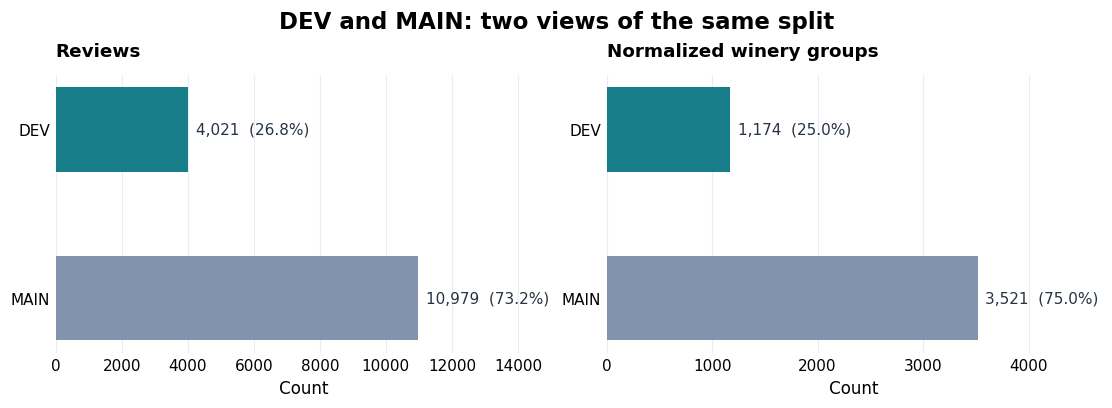

In [34]:
# Section 5.4a — Size of the two data partitions

partition_names = ["DEV", "MAIN"]
partition_colors = ["#177E89", "#8294AD"]

review_counts = [len(dev), len(main)]
winery_counts = [
    dev["winery_group"].nunique(),
    main["winery_group"].nunique(),
]

panels = [
    ("Reviews", review_counts, len(full)),
    (
        "Normalized winery groups",
        winery_counts,
        full["winery_group"].nunique(),
    ),
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 3.6),
    layout="constrained",
    facecolor="white",
)

for ax, (title, counts, total) in zip(axes, panels):
    bars = ax.barh(
        partition_names,
        counts,
        color=partition_colors,
        height=0.5,
        zorder=3,
    )

    for bar, count in zip(bars, counts):
        ax.text(
            count + total * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{count:,}  ({100 * count / total:.1f}%)",
            va="center",
            fontsize=10,
            color="#263445",
        )

    ax.invert_yaxis()
    ax.set_xlim(0, total)
    ax.set_xlabel("Count")
    ax.set_title(title, loc="left", fontweight="bold", pad=12)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E9EDF2", linewidth=0.8)
    ax.tick_params(axis="both", length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "DEV and MAIN: two views of the same split",
    fontsize=15,
    fontweight="bold",
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "f2c_dev_main_composition.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

**What the two plots show.** DEV contains 1,174 of the 4,695 winery groups (25.0%, rounded), but 4,021 of the 15,000 reviews (26.8%). MAIN contains the remaining 3,521 groups and 10,979 reviews. The review share in DEV is about 1.8 percentage points above its group share. This is not a split error: `GroupShuffleSplit` samples whole winery groups, and those groups do not all contain the same number of reviews. Splitting individual reviews just to obtain exactly 25% would defeat the group-separation rule.

**Is the split usable?** The overall review share is inside our declared 20%–30% range. The table above also shows that class shares are 19.0%–21.1% in DEV and 19.6%–20.4% in MAIN, inside the declared 15%–25% range. DEV includes at least 222 winery groups for every class, compared with our minimum of 25. These checks support using the split for the planned grouped cross-validation. The no-overlap assertion establishes separation; the bar lengths alone do not.

We therefore retain seed 43 under the predeclared acceptance rule. We do not try more seeds to make the bars closer to exactly 25% or to obtain a preferred model score. This checks class coverage and group separation, not whether DEV and MAIN have identical country, taster or writing-style distributions.

#### 5.4b How big are the wineries?

Grouping by winery works well only when no single winery is huge. A winery with thousands of reviews would have to go to one side of every split and would pull the folds out of balance. The figure checks this before we trust the folds. It also shows how many wineries make more than one grape, which is why we group by winery alone and not by winery and grape.

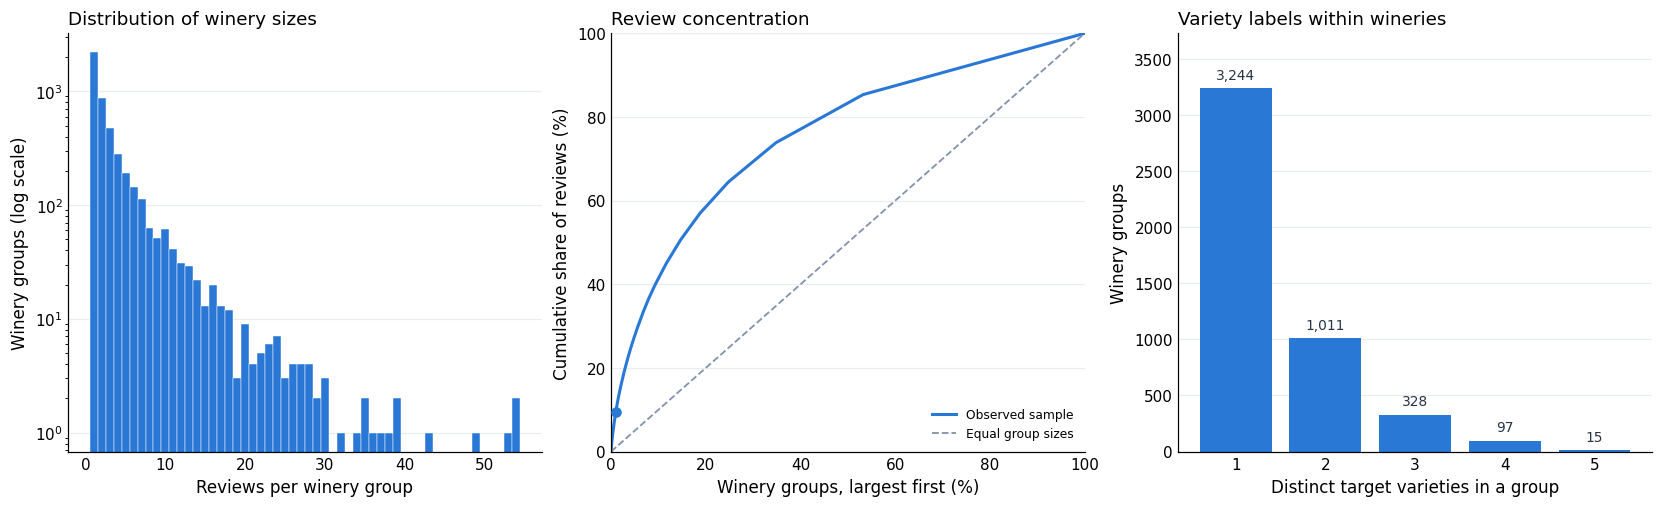

In [35]:
# Section 5.4b — Winery sizes and shared variety labels
from IPython.display import display, Markdown

if "full" not in globals():
    raise NameError("Run Section 5.1 first: it creates full.")

required = {"winery_group", "variety"}
missing = required - set(full.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

if full.empty or full[list(required)].isna().any().any():
    raise ValueError("The sample is empty or has missing grouping/label values.")

# Local colours: no additional settings cell is needed.
STRUCTURE_COLOR = "#2A78D6"
REFERENCE_COLOR = "#8294AD"
TEXT_COLOR = "#263445"

reviews_per_winery = (
    full.groupby("winery_group")
    .size()
    .sort_values(ascending=False)
)

grapes_per_winery = (
    full.groupby("winery_group")["variety"]
    .nunique()
)

sizes = reviews_per_winery.to_numpy()
n_wineries = len(sizes)
n_reviews = int(sizes.sum())

# Largest groups first; include the origin.
cumulative_reviews = np.r_[
    0.0,
    100 * np.cumsum(sizes) / n_reviews,
]
cumulative_wineries = np.linspace(0, 100, n_wineries + 1)

# Round up to include at least 1% of groups.
top_n = max(1, int(np.ceil(0.01 * n_wineries)))
top_group_pct = 100 * top_n / n_wineries
top_review_pct = 100 * sizes[:top_n].sum() / n_reviews

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    layout="constrained",
    facecolor="white",
)

# 1. Distribution of group sizes.
ax = axes[0]

ax.hist(
    sizes,
    bins=np.arange(1, sizes.max() + 2) - 0.5,
    color=STRUCTURE_COLOR,
    edgecolor="white",
    linewidth=0.3,
)

ax.set_yscale("log")
ax.set_xlabel("Reviews per winery group")
ax.set_ylabel("Winery groups (log scale)")
ax.set_title("Distribution of winery sizes", loc="left")

# 2. Concentration of reviews in the largest groups.
ax = axes[1]

ax.plot(
    cumulative_wineries,
    cumulative_reviews,
    color=STRUCTURE_COLOR,
    linewidth=2,
    label="Observed sample",
)

ax.plot(
    [0, 100],
    [0, 100],
    color=REFERENCE_COLOR,
    linestyle="--",
    linewidth=1.2,
    label="Equal group sizes",
)

ax.scatter(
    [top_group_pct],
    [top_review_pct],
    color=STRUCTURE_COLOR,
    s=35,
    zorder=4,
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("Winery groups, largest first (%)")
ax.set_ylabel("Cumulative share of reviews (%)")
ax.set_title("Review concentration", loc="left")
ax.legend(frameon=False, loc="lower right", fontsize=8)

# 3. How many target labels occur within each group?
ax = axes[2]

grape_counts = (
    grapes_per_winery.value_counts()
    .reindex(range(1, len(CLASSES) + 1), fill_value=0)
)

bars = ax.bar(
    grape_counts.index.astype(str),
    grape_counts.to_numpy(),
    color=STRUCTURE_COLOR,
)

ax.bar_label(
    bars,
    labels=[f"{int(value):,}" for value in grape_counts],
    padding=4,
    fontsize=9,
    color=TEXT_COLOR,
)

ax.set_ylim(0, max(1, grape_counts.max()) * 1.15)
ax.set_xlabel("Distinct target varieties in a group")
ax.set_ylabel("Winery groups")
ax.set_title("Variety labels within wineries", loc="left")

for ax in axes:
    ax.grid(axis="y", color="#E9EDF2", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "f2f_winery_structure.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

multi_grape = int(grapes_per_winery.gt(1).sum())

#### What the winery structure means for validation

**Group sizes are uneven.** The median winery group contains
2 reviews, while the mean is 3.2. The histogram shows many small
groups and a smaller number of larger groups. Its vertical axis
is logarithmic, so equal vertical distances represent multiplicative
rather than additive differences in group counts.

**There is concentration, but no single group dominates the sample.**
The largest group contains 54 of 15,000 reviews: 0.36%, displayed
as 0.4%. The largest 47 groups, approximately 1% of all groups,
account for 9.5% of reviews. The cumulative curve lies above the
equal-size diagonal because groups are accumulated from largest
to smallest. These figures describe review concentration; they
do not establish how strongly any winery influences predictions.

**Winery groups can contain several target varieties.**
Of the 4,695 groups, 3,244 contain one target variety and 1,451
(30.9%) contain more than one. This describes the selected sample,
not the complete product range of each winery. Grouping by a
winery–variety pair would split some winery groups and could place
the same winery in both training and testing.

**Our decision.** We retain winery_group alone as the grouping key.
Unequal group sizes and class compositions can make exact balance
difficult, so Section 5.5 checks the actual folds against the
predeclared coverage and separation rules. These plots explain
why those checks are needed; they do not replace them.

### 5.5 Shared folds

**MAIN.** `StratifiedGroupKFold` makes five folds. Every winery sits in exactly one test fold, and the grape shares stay close to equal. We do this three times, with seeds 42, 43 and 44, which gives up to 15 scores per model. **DEV.** The same function, one repeat, used only for tuning.

The folds are made once, here. Models never make their own folds. This is how all of them are compared on the same test reviews.

Stratifying by groups is only approximate, so the code checks every fold against the rules from 5.2:

- Train and test share no review and no winery.
- All five grapes appear in every train part and every test part.
- Every grape is 10% to 30% of each test fold, and has at least five different wineries there.
- In one repeat, every review is in a test fold exactly once.
- The three repeats are really different from each other.

In [36]:
# Section 5.5 — Shared folds

def make_group_folds(frame, n_repeats, n_splits=N_SPLITS, seed=SEED):
    """One list of (train_positions, test_positions) per repeat. Repeat r uses seed + r."""
    folds_by_repeat = []
    for repeat in range(n_repeats):
        splitter = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=seed + repeat
        )
        folds_by_repeat.append([
            (np.sort(train), np.sort(test))
            for train, test in splitter.split(
                np.zeros(len(frame)), frame["variety"], groups=frame["winery_group"]
            )
        ])
    return folds_by_repeat


def fold_ids(n_rows, folds):
    """For every row: the number of the test fold it belongs to."""
    ids = np.full(n_rows, -1, dtype=int)
    for fold_number, (_, test) in enumerate(folds):
        ids[test] = fold_number
    return ids


def check_folds(frame, folds_by_repeat, label):
    y = frame["variety"]
    wineries = frame["winery_group"]
    rows = []

    for repeat, folds in enumerate(folds_by_repeat):
        seen = np.zeros(len(frame), dtype=int)

        for fold_number, (train, test) in enumerate(folds):
            assert len(np.intersect1d(train, test)) == 0, "a review is in train and test"
            assert set(wineries.iloc[train]).isdisjoint(set(wineries.iloc[test])), \
                "a winery is in train and test"
            assert set(y.iloc[train]) == set(CLASSES), "a grape is missing in train"
            assert set(y.iloc[test]) == set(CLASSES), "a grape is missing in test"
            seen[test] += 1

            test_shares = y.iloc[test].value_counts(normalize=True).reindex(CLASSES, fill_value=0)
            test_wineries = (
                wineries.iloc[test].groupby(y.iloc[test]).nunique().reindex(CLASSES, fill_value=0)
            )
            assert test_shares.min() >= FOLD_CLASS_SHARE_RANGE[0], "a grape is too rare in a test fold"
            assert test_shares.max() <= FOLD_CLASS_SHARE_RANGE[1], "a grape is too common in a test fold"
            assert test_wineries.min() >= MIN_TEST_WINERIES_PER_CLASS, "too few wineries for a grape in a test fold"

            rows.append({
                "part": label, "repeat": repeat, "fold": fold_number,
                "train_reviews": len(train), "test_reviews": len(test),
                "test_wineries": wineries.iloc[test].nunique(),
                "smallest_class_share_%": round(100 * test_shares.min(), 1),
                "largest_class_share_%": round(100 * test_shares.max(), 1),
                "fewest_wineries_for_a_grape": int(test_wineries.min()),
            })

        assert (seen == 1).all(), "every review must be in a test fold exactly once per repeat"

    # Compare every pair, ignoring a mere renaming of fold numbers.
    partitions = [
        frozenset(frozenset(test.tolist()) for _, test in folds)
        for folds in folds_by_repeat
    ]
    for left in range(len(partitions)):
        for right in range(left + 1, len(partitions)):
            assert partitions[left] != partitions[right], (
                f"Repeats {left} and {right} define the same test partition."
            )

    return pd.DataFrame(rows)


main_folds = make_group_folds(main, N_REPEATS)
dev_folds = make_group_folds(dev, 1)[0]          # DEV: one repeat, so just the list of five folds

main_fold_table = check_folds(main, main_folds, "MAIN")
dev_fold_table = check_folds(dev, [dev_folds], "DEV")

print("All fold checks passed.")
display(pd.concat([main_fold_table, dev_fold_table], ignore_index=True))

All fold checks passed.


,part,repeat,fold,train_reviews,test_reviews,test_wineries,smallest_class_share_%,largest_class_share_%,fewest_wineries_for_a_grape
0,MAIN,0,0,8856,2123,709,15.8,21.6,128
1,MAIN,0,1,8670,2309,710,16.8,21.8,127
2,MAIN,0,2,8765,2214,699,18.2,22.4,127
3,MAIN,0,3,8804,2175,702,18.5,22.7,131
4,MAIN,0,4,8821,2158,701,18.5,22.4,128
5,MAIN,1,0,9030,1949,706,17.3,23.8,126
6,MAIN,1,1,8707,2272,703,18.6,22.3,124
7,MAIN,1,2,8774,2205,701,18.3,21.6,133
8,MAIN,1,3,8679,2300,700,17.3,21.6,124
9,MAIN,1,4,8726,2253,711,17.9,22.7,134


**Grape shares in each test fold** (MAIN, first repeat). If grouping had broken the balance, we would see it here.

In [37]:
# Section 5.5b — Grape shares in each test fold (MAIN, first repeat)

share_rows = []
for fold_number, (_, test) in enumerate(main_folds[0]):
    shares = main["variety"].iloc[test].value_counts(normalize=True).reindex(CLASSES, fill_value=0)
    share_rows.append({"fold": fold_number, **(100 * shares).round(1).to_dict()})

display(pd.DataFrame(share_rows).set_index("fold"))
print("Shares are in % of the test fold. Perfect balance would be 20.0 everywhere.")

,Chardonnay,Riesling,Pinot Noir,Cabernet Sauvignon,Syrah
fold,,,,,
0,20.6,15.8,20.7,21.6,21.2
1,21.0,19.7,16.8,20.7,21.8
2,18.3,22.4,20.1,18.2,21.0
3,19.6,20.0,22.7,19.2,18.5
4,18.5,22.4,18.9,21.0,19.3


Shares are in % of the test fold. Perfect balance would be 20.0 everywhere.


**Class balance across all shared folds.** The same colour scale is used for DEV and all MAIN repeats. Each cell is a percentage within one test fold; 20% is equal balance. This checks the evaluation design without inspecting MAIN review text. Different shares within the accepted range are expected when whole winery groups stay together.

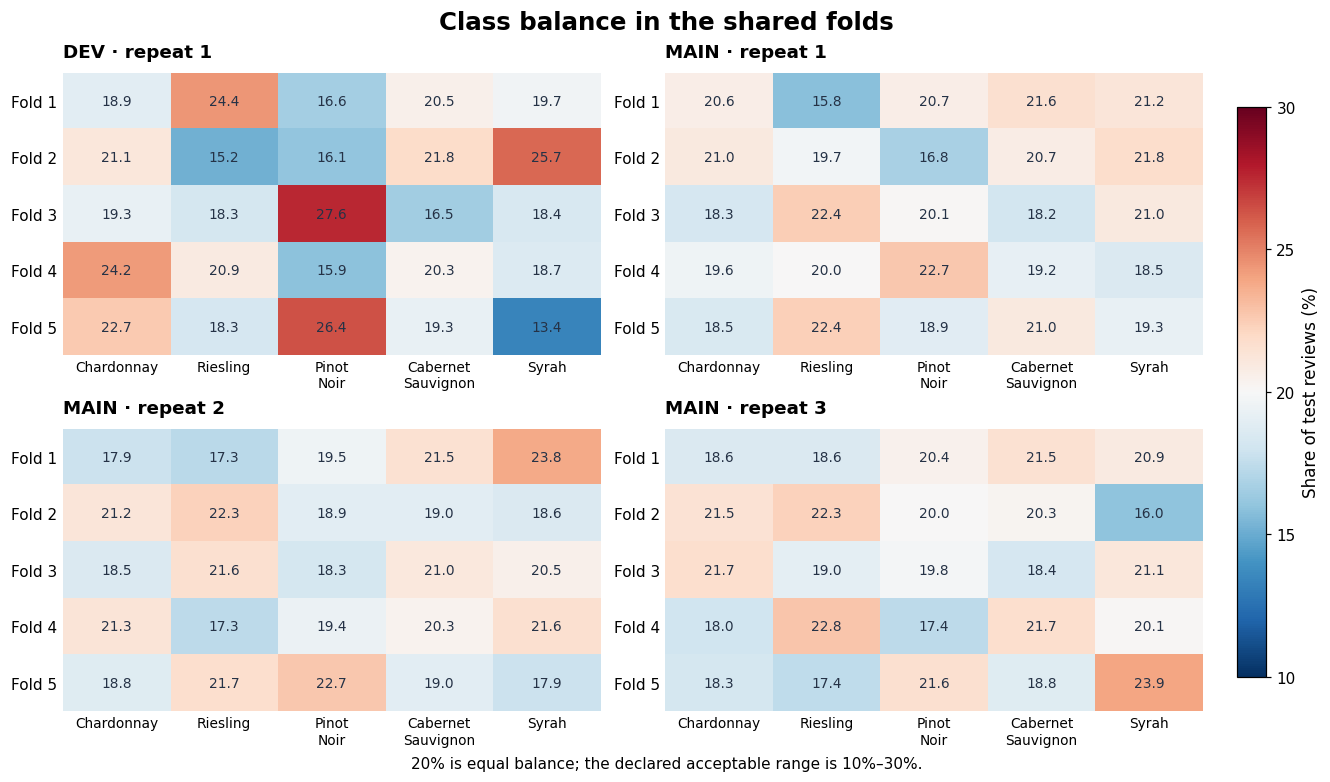

In [38]:
# Section 5.5c — Class balance in every shared test fold

panels = [("DEV · repeat 1", dev, dev_folds)]
panels += [
    (f"MAIN · repeat {repeat + 1}", main, folds)
    for repeat, folds in enumerate(main_folds)
]

ncols = 2
nrows = (len(panels) + ncols - 1) // ncols
fig, axes = plt.subplots(
    nrows, ncols, figsize=(12, 3.5 * nrows),
    squeeze=False, layout="constrained", facecolor="white",
)
balance_rows = []

for ax, (title, frame, folds) in zip(axes.flat, panels):
    values = np.vstack([
        100 * frame["variety"].iloc[test]
        .value_counts(normalize=True).reindex(CLASSES, fill_value=0).to_numpy()
        for _, test in folds
    ])
    image = ax.imshow(values, cmap="RdBu_r", vmin=10, vmax=30, aspect="auto")
    ax.set_title(title, loc="left", fontweight="bold", pad=10)
    ax.set_xticks(np.arange(len(CLASSES)))
    ax.set_xticklabels([name.replace(" ", "\n") for name in CLASSES], fontsize=9)
    ax.set_yticks(np.arange(len(folds)))
    ax.set_yticklabels([f"Fold {number + 1}" for number in range(len(folds))])
    ax.tick_params(axis="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            ax.text(column, row, f"{values[row, column]:.1f}",
                    ha="center", va="center", fontsize=9, color="#253246")
        balance_rows.append({
            "panel": title, "fold": row,
            **dict(zip(CLASSES, values[row])),
        })

for ax in list(axes.flat)[len(panels):]:
    ax.set_visible(False)

colorbar = fig.colorbar(
    image, ax=list(axes.flat)[:len(panels)], fraction=0.025, pad=0.03,
)
colorbar.set_label("Share of test reviews (%)")
colorbar.set_ticks([10, 15, 20, 25, 30])
fig.suptitle("Class balance in the shared folds", fontsize=16, fontweight="bold")
fig.supxlabel("20% is equal balance; the declared acceptable range is 10%–30%.", fontsize=10)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
diagnostics_dir = RESULTS_DIR / "validation_diagnostics"
diagnostics_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame(balance_rows).to_csv(diagnostics_dir / "test_fold_class_shares.csv", index=False)
fig.savefig(FIGURES_DIR / "f2a_fold_class_balance.png", dpi=200, bbox_inches="tight")
plt.show()

#### Reading the fold-balance heatmaps

**The balance is approximate.** Equal class shares would be 20% in every cell. Across all MAIN repeats, the observed shares range from 15.8% to 23.9%; across the DEV folds, they range from 13.4% to 27.6%. For example, Syrah is 13.4% of DEV Fold 5, while Pinot Noir is 27.6% of DEV Fold 3. The DEV folds are less evenly balanced by this range, but every displayed share is inside the 10%–30% interval we fixed before splitting.

**Why do the colours differ if the sample is balanced?** We balanced the complete sample by grape, not each winery group. A winery can contribute many reviews of one grape and few of another, and the splitter must move those reviews together. DEV also has fewer groups than MAIN (1,174 versus 3,521), so balancing whole groups has fewer opportunities to average out their different compositions. This helps explain the pattern, but the heatmap by itself does not isolate the contribution of each factor. Grouped stratification aims to preserve class proportions; it does not promise exact 20% shares or equal fold sizes.

**Our decision.** We keep these folds because the checks and tables in Section 5.5 confirm that every class occurs in training and testing, every test fold has enough winery groups per class, and train/test winery groups are disjoint. The smallest class-specific winery count is 39 in a DEV test fold and 118 in a MAIN test fold, above our minimum of five. The heatmap shows class proportions; group separation is established by the code checks, not by the colours. Test-fold sizes also vary: 696–972 reviews in DEV and 1,933–2,424 in MAIN. Macro-F1 will give each class equal weight, but it does not remove uncertainty caused by different test-set sizes and compositions.

Fold names in the plots start at 1 for readability; the saved fold IDs and the preceding tables start at 0. MAIN repeats use the same reviews with different group assignments, so their future scores will not be 15 independent measurements.

### 5.6 Why grouping matters: ordinary folds for comparison

Experiment E2 compares grouped folds with ordinary stratified folds on the same reviews. We build the ordinary folds here so that they are shared too. They are **not** used for the main results.

The table shows the reason for grouping: in ordinary folds many test reviews come from a winery the model has already seen in training. In grouped folds this share is zero by construction.

In [39]:
# Section 5.6 — Ordinary (not grouped) folds, only for experiment E2

def make_naive_folds(frame, n_repeats, n_splits=N_SPLITS, seed=SEED):
    folds_by_repeat = []
    for repeat in range(n_repeats):
        splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed + repeat)
        folds_by_repeat.append([
            (np.sort(train), np.sort(test))
            for train, test in splitter.split(np.zeros(len(frame)), frame["variety"])
        ])
    return folds_by_repeat


def seen_winery_share(frame, folds_by_repeat):
    """Percent of test reviews whose winery also appears in the training part."""
    shares = []
    for folds in folds_by_repeat:
        for train, test in folds:
            train_wineries = set(frame["winery_group"].iloc[train])
            shares.append(100 * frame["winery_group"].iloc[test].isin(train_wineries).mean())
    return np.array(shares)

naive_folds = make_naive_folds(main, N_REPEATS)

naive_seen = seen_winery_share(main, naive_folds)
grouped_seen = seen_winery_share(main, main_folds)

leak_table = pd.DataFrame({
    "fold type": ["ordinary (stratified)", "grouped by winery (ours)"],
    "mean % of test reviews from a winery seen in training": [
        round(naive_seen.mean(), 1), round(grouped_seen.mean(), 1)
    ],
    "smallest": [round(naive_seen.min(), 1), round(grouped_seen.min(), 1)],
    "largest": [round(naive_seen.max(), 1), round(grouped_seen.max(), 1)],
})
display(leak_table)
assert grouped_seen.max() == 0

,fold type,mean % of test reviews from a winery seen in training,smallest,largest
0,ordinary (stratified),82.1,80.2,83.6
1,grouped by winery (ours),0.0,0.0,0.0


**How much group overlap ordinary folds permit.** This comparison uses the same MAIN reviews and reports overlap of recorded winery groups. It does not yet compare classifier performance. Whiskers show the observed range across folds, not a confidence interval.

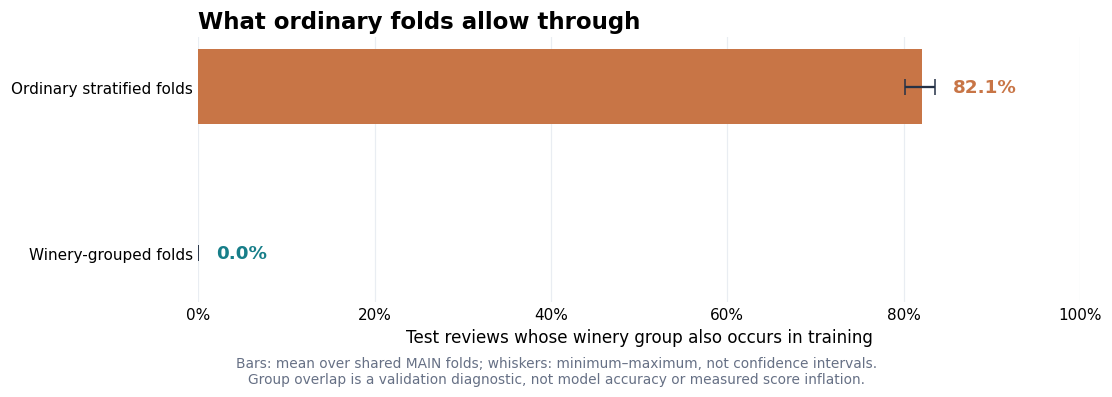

In [40]:
# Section 5.6b — Group overlap: ordinary versus grouped validation

means = np.array([naive_seen.mean(), grouped_seen.mean()])
minimums = np.array([naive_seen.min(), grouped_seen.min()])
maximums = np.array([naive_seen.max(), grouped_seen.max()])
labels = ["Ordinary stratified folds", "Winery-grouped folds"]
colors = ["#C87546", "#177E89"]

fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained", facecolor="white")
ax.barh(np.arange(2), means, color=colors, height=0.45, zorder=2)
ax.errorbar(
    means, np.arange(2),
    xerr=np.vstack([means - minimums, maximums - means]),
    fmt="none", ecolor="#253246", capsize=5, linewidth=1.5, zorder=3,
)
for position, mean in enumerate(means):
    ax.text(maximums[position] + 2, position, f"{mean:.1f}%",
            va="center", fontweight="bold", color=colors[position], fontsize=12)
ax.set_yticks(np.arange(2))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_xticklabels([f"{value}%" for value in range(0, 101, 20)])
ax.set_xlabel("Test reviews whose winery group also occurs in training")
ax.set_title("What ordinary folds allow through", loc="left", fontsize=15, fontweight="bold")
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E9EDF2")
ax.tick_params(axis="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.supxlabel(
    "Bars: mean over shared MAIN folds; whiskers: minimum–maximum, not confidence intervals.\n"
    "Group overlap is a validation diagnostic, not model accuracy or measured score inflation.",
    fontsize=9, color="#667085",
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / "f2b_winery_overlap.png", dpi=200, bbox_inches="tight")
plt.show()

#### What the overlap comparison means

**The difference is large, but it is not an accuracy difference.** In ordinary stratified cross-validation, an average of 82.1% of test reviews come from a winery group also present in the corresponding training set; the range is 80.2%–83.6%. In grouped cross-validation, this share is exactly 0% in every checked fold. The denominator is the number of test reviews in each fold, not the number of distinct wineries. A winery contributes through all of its test reviews, but a review counts as overlap only if its winery group also occurs in training.

**Why does ordinary splitting allow this?** Ordinary stratification balances grape labels while assigning individual reviews. It has no constraint that keeps reviews from the same winery together. The training set may therefore contain vocabulary, producer references or writing patterns associated with a test review's winery. That makes ordinary cross-validation answer a different question: performance on held-out reviews that can come from familiar wineries. Our main question concerns held-out winery groups, so grouped folds are the appropriate primary scheme.

**What we can conclude now.** The 0% result confirms that recorded winery groups do not cross the train/test boundary. It does not prove that the classifier would recognize wineries, that ordinary validation inflates macro-F1 by 82.1 percentage points, or that all possible leakage has been removed. We have not measured a model-score difference in this section. The optional E2 experiment must fit the same chosen LogisticRegression configuration under both schemes on the same MAIN reviews, using the same text version and a fresh preprocessing pipeline inside each training fold. Only that comparison can quantify the observed score difference for this setup.

The whiskers show the minimum and maximum overlap across the 15 folds. They are descriptive ranges, not confidence intervals. We retain grouped folds for the primary results regardless of whether E2 later finds a large, small or reversed score difference.

### 5.7 Saving the split and the folds

Everyone has to use the same split and the same folds, so we save them as small CSV files. They store `row_id`, which points to the row in the original Kaggle file, so they are readable without this notebook.

As with the shared sample, files that already exist are **never overwritten**. If they exist, we build the split again in memory and check that it is byte for byte the same. If it is not, the notebook stops. This proves that the split can be repeated, and it protects the frozen files.

| File | What it holds |
|---|---|
| `split_assignment.csv` | For every review: DEV or MAIN |
| `folds_main.csv` | For every MAIN review: its test fold in each repeat |
| `folds_dev.csv` | For every DEV review: its test fold |
| `validation_manifest.json` | Hashes of the files above, the sample hash, the split seed and the rules |

In [41]:
# Section 5.7 — Save or verify the frozen split and folds

VALIDATION_DIR = RESULTS_DIR / "validation"
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = VALIDATION_DIR / "validation_manifest.json"


def csv_bytes(table):
    return table.sort_values("row_id").to_csv(index=False, lineterminator="\n").encode("utf-8")


assignment_table = full[["row_id"]].copy()
assignment_table["part"] = "MAIN"
assignment_table.loc[dev_positions, "part"] = "DEV"

main_fold_file = main[["row_id"]].copy()
for repeat, folds in enumerate(main_folds):
    main_fold_file[f"fold_repeat{repeat}"] = fold_ids(len(main), folds)

dev_fold_file = dev[["row_id"]].copy()
dev_fold_file["fold"] = fold_ids(len(dev), dev_folds)

new_files = {
    "split_assignment.csv": csv_bytes(assignment_table),
    "folds_main.csv": csv_bytes(main_fold_file),
    "folds_dev.csv": csv_bytes(dev_fold_file),
}
new_hashes = {name: hashlib.sha256(data).hexdigest() for name, data in new_files.items()}

if MANIFEST_PATH.exists():
    frozen = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

    if frozen["sample_sha256"] != sample_hash:
        raise ValueError(
            "The frozen split belongs to a different sample. "
            "Restore the matching files from the team repository."
        )
    for name, expected in frozen["file_hashes"].items():
        path = VALIDATION_DIR / name
        if not path.is_file():
            raise FileNotFoundError(f"Frozen file is missing: {path}")
        if sha256_file(path) != expected:
            raise ValueError(f"{name} was changed after it was frozen.")
    if frozen["split_seed"] != SPLIT_SEED or frozen["file_hashes"] != new_hashes:
        raise ValueError(
            "The split built now differs from the frozen split. "
            "Existing files were not overwritten. Check the sample, the seeds "
            "and the library versions."
        )
    save_status = "Existing split and folds verified; files unchanged."

else:
    existing_files = [
        name
        for name in new_files
        if (VALIDATION_DIR / name).exists()
    ]

    if existing_files:
        raise FileExistsError(
            "Validation CSV files exist without validation_manifest.json: "
            + ", ".join(existing_files)
            + ". Restore the matching complete set from the team repository "
            "before continuing. Existing files were not overwritten."
        )

    for name, data in new_files.items():
        (VALIDATION_DIR / name).write_bytes(data)

    manifest = {
        "sample_sha256": sample_hash,
        "split_seed": SPLIT_SEED,
        "split_seed_candidates": SPLIT_SEED_CANDIDATES,
        "dev_group_fraction": DEV_GROUP_FRACTION,
        "n_splits": N_SPLITS,
        "n_repeats": N_REPEATS,
        "fold_seeds": [SEED + r for r in range(N_REPEATS)],
        "rules": {
            "dev_share_range": DEV_SHARE_RANGE,
            "class_share_range": CLASS_SHARE_RANGE,
            "min_wineries_per_class": MIN_WINERIES_PER_CLASS,
            "fold_class_share_range": FOLD_CLASS_SHARE_RANGE,
            "min_test_wineries_per_class": MIN_TEST_WINERIES_PER_CLASS,
        },
        "file_hashes": new_hashes,
        "scikit_learn": metadata.version("scikit-learn"),
        "numpy": metadata.version("numpy"),
        "pandas": metadata.version("pandas"),
    }
    MANIFEST_PATH.write_text(
        json.dumps(manifest, indent=2, ensure_ascii=False) + "\n", encoding="utf-8"
    )
    save_status = "New split and folds saved."


# Read the files back and rebuild the folds from them. They must equal the folds in memory.
def folds_from_file(file_table, frame):
    if file_table["row_id"].isna().any() or not file_table["row_id"].is_unique:
        raise ValueError("Fold-file row_id values must be filled and unique.")
    if set(file_table["row_id"]) != set(frame["row_id"]):
        raise ValueError("Fold-file row_id values do not match the data partition.")
    folds_by_repeat = []
    for column in [c for c in file_table.columns if c.startswith("fold")]:
        ids = file_table.set_index("row_id")[column].reindex(frame["row_id"].values).to_numpy()
        if not np.isin(ids, np.arange(N_SPLITS)).all():
            raise ValueError(f"Invalid or missing fold IDs in {column}.")
        folds = []
        for fold_number in range(N_SPLITS):
            test = np.where(ids == fold_number)[0]
            train = np.where(ids != fold_number)[0]
            folds.append((train, test))
        folds_by_repeat.append(folds)
    return folds_by_repeat

reloaded_main = folds_from_file(pd.read_csv(VALIDATION_DIR / "folds_main.csv"), main)
reloaded_dev = folds_from_file(pd.read_csv(VALIDATION_DIR / "folds_dev.csv"), dev)[0]

for repeat in range(N_REPEATS):
    for fold_number in range(N_SPLITS):
        assert np.array_equal(reloaded_main[repeat][fold_number][1], main_folds[repeat][fold_number][1])
for fold_number in range(N_SPLITS):
    assert np.array_equal(reloaded_dev[fold_number][1], dev_folds[fold_number][1])

reloaded_assignment = pd.read_csv(VALIDATION_DIR / "split_assignment.csv")
assert set(reloaded_assignment.loc[reloaded_assignment["part"] == "DEV", "row_id"]) == set(dev["row_id"])
assert set(reloaded_assignment.loc[reloaded_assignment["part"] == "MAIN", "row_id"]) == set(main["row_id"])

print(save_status)
print("Folder:", VALIDATION_DIR)
for name, value in new_hashes.items():
    print(f"  {name}: {value[:16]}…")
print("Saved files match the folds in memory.")

New split and folds saved.
Folder: /content/results/validation
  split_assignment.csv: 1b722ae8833c4ed3…
  folds_main.csv: 9d4b18beff9457cc…
  folds_dev.csv: 679382ca0b0ce7ac…
Saved files match the folds in memory.


### 5.8 What these checks guarantee, and what they do not

**What the checks establish.** No normalized winery group is shared between DEV and MAIN. Within every fold, training and test reviews have disjoint winery groups. All five classes occur in both parts and meet the declared test-fold coverage rules. Every review is tested exactly once per repeat. The saved assignments can be reloaded and checked against the assignments in memory. All three models and all text versions must use these shared files.

**What they do not establish.** Grouping prevents overlap of the recorded winery groups; it does not eliminate every possible shortcut or prove the absence of all data leakage. Producer aliases may remain separate groups, and near-duplicate reviews may remain. Class balance is approximate. The heatmaps show the observed proportions; the checks enforce the declared acceptance limits.

The split and fold procedure is deterministic for the same inputs, row order, settings and compatible software environment. The manifest records package versions. Team members should load the frozen assignments by `row_id`; regenerating them with a different scikit-learn version may produce different folds even with the same seeds. A verification mismatch must be investigated rather than bypassed by replacing the reference files.

MAIN folds are not independent: training sets overlap and repeats reuse the same reviews. Standard deviation across fold scores is descriptive spread, not a confidence interval or a test of statistical significance.

### 5.9 Decision and next step

For the frozen 15,000-review sample and scikit-learn 1.6.1, seed 43 is the first candidate that passes the declared DEV/MAIN rules. The five DEV folds and all fifteen MAIN folds pass the group-separation and class-coverage checks. The saved assignments were read back and verified against the folds in memory.

We retain and share these assignments. The plots describe partition sizes, winery-group structure,
approximate class balance and train/test winery-group overlap. None is a measure of classifier performance, and none is a reason to keep changing seeds after model results become available.

The next steps are to finish the common L0–L3 masking functions and evaluation utilities, tune each classifier on DEV, and freeze those choices before the final MAIN comparison. Classifiers must receive only the corresponding version of `description`, and all learned preprocessing must be fitted within each training fold. All models and text versions must use the same frozen assignments and agreed number of repeats.

The validation design is ready for those experiments. Whether masking lowers macro-F1, which model performs best, and how grouped versus ordinary validation changes predictive scores remain unanswered at this stage.

## 6. Masking L0 to L3

We build four versions of every review: L0 basic cleanup only, L1 target grape names removed, L2 also other grapes, L3 also places, origin adjectives and this review's own winery name. The word lists come from the raw Kaggle file, using only rows of other grapes and are checked on DEV only. Taste words such as petrol, tannin or oak are never removed.

In [42]:
from pathlib import Path
Path("masking").mkdir(exist_ok=True)

[текст посилання](https://)

# Section 6.2 *Check that the three word lists are in place*

In [43]:
LIST_FILES = {
    "target_varieties.txt": MASKING_DIR / "target_varieties.txt",
    "other_grapes.txt": MASKING_DIR / "other_grapes.txt",
    "geography.txt": MASKING_DIR / "geography.txt",
}
for name, path in LIST_FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Upload {name} into the 'masking' folder first.")
print("All three word lists found.")

All three word lists found.


# Section 6.3 *Masking functions*
**Choices and limits of the masking rules.**
- Standalone *Pinot*, *Cabernet* and *Cab* are treated as broad name cues. They are not unique identifiers of the target varieties and can also remove parts of other grape names (for example *Pinot Grigio* becomes *Grigio* at L1). Consequently, L1 and L2 do not provide a perfectly separated removal of target and non-target grape information.
- Plural endings are allowed only for grape names. Place and winery names are matched exactly (apart from *'s*), so that *chiles* (the pepper) is not removed together with *Chile*.
- L3 uses the winery name of each review. The classifier only receives the processed text, but preparing that text needs this metadata, so L3 is not a fully autonomous system.
- Taste words (petrol, tannin, oak, fruit names) are never removed. Place names that contain such a word (for example *Dry Creek*, *Oak Knoll*) are removed only as whole phrases.
- Remaining place, winery and classification words on DEV (for example *Vineyard*, *Cru*, *Premier*, owners' first names) are not removed. This is a known incompleteness of the lists.

In [44]:
import unicodedata
from collections import Counter

def norm(text):
    if not isinstance(text, str):
        raise TypeError("Masking expects a string.")
    text = text.translate(str.maketrans({
        "\u2018": "'", "\u2019": "'",
        "\u2010": "-", "\u2011": "-", "\u2012": "-",
        "\u2013": "-", "\u2014": "-", "\u2212": "-",
    }))
    text = unicodedata.normalize("NFKD", text)
    text = "".join(c for c in text if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", text).strip()

def build_pattern(terms=(), exact_terms=()):
    plural = {norm(t) for t in terms if norm(t)}
    exact = {norm(t) for t in exact_terms if norm(t)} - plural
    ordered = sorted(plural | exact, key=lambda t: (-len(t), t))
    if not ordered:
        return re.compile(r"(?!)")
    parts = []
    for t in ordered:
        core = r"[\s-]+".join(re.escape(w) for w in re.split(r"[\s-]+", t) if w)
        parts.append(core + (r"(?:'s|s)?" if t in plural else r"(?:'s)?"))
    return re.compile(r"(?<!\w)(?:" + "|".join(parts) + r")(?!\w)", flags=re.IGNORECASE)

def read_terms(path):
    lines = Path(path).read_text(encoding="utf-8").splitlines()
    return [ln.strip() for ln in lines if ln.strip() and not ln.lstrip().startswith("#")]


def remove_terms(text, pattern):
    current = norm(text)
    while True:
        updated = norm(pattern.sub(" ", current))
        if updated == current:
            return updated
        current = updated

def mask_winery(text, winery):
    return remove_terms(text, build_pattern(exact_terms=[winery]))

def build_ladder(frame, l1_terms, other_terms, geo_terms):
    p1 = build_pattern(l1_terms)
    p2 = build_pattern(l1_terms + other_terms)
    p3 = build_pattern(l1_terms + other_terms, exact_terms=geo_terms)
    base = frame["description"].map(norm)
    l3 = [remove_terms(mask_winery(t, w), p3)
          for t, w in zip(base, frame["winery"])]
    return {
        "L0": base,
        "L1": base.map(lambda t: remove_terms(t, p1)),
        "L2": base.map(lambda t: remove_terms(t, p2)),
        "L3": pd.Series(l3, index=frame.index),
    }

print("Masking functions defined.")

Masking functions defined.


# Section 6.4 *Tests on invented examples (no real data)*

In [45]:
L1_TERMS = read_terms(LIST_FILES["target_varieties.txt"])
OTHER_TERMS = read_terms(LIST_FILES["other_grapes.txt"])
GEO_TERMS = read_terms(LIST_FILES["geography.txt"])
print("Terms per list:", len(L1_TERMS), len(OTHER_TERMS), len(GEO_TERMS))

p1 = build_pattern(L1_TERMS)
p3 = build_pattern(L1_TERMS + OTHER_TERMS, exact_terms=GEO_TERMS)

out = remove_terms("Chardonnay, CHARDONNAY, Pinot-Noir and Riesling's charm.", p1)
assert not re.search(r"chardonnay|pinot|riesling", out, re.I)
assert "cabinet" in remove_terms("A cabinet of Cab flavours.", p1)
assert remove_terms("some text", build_pattern([])) == "some text"
out = remove_terms("Petrol, oak and firm tannin.", p1)
assert all(w in out for w in ["Petrol", "oak", "tannin"])

for dash in ["-", "\u2010", "\u2011", "\u2013", "\u2014"]:
    assert remove_terms(f"Pinot{dash}Noir", p1) == ""

assert remove_terms("Pinot Merlot Noir", build_pattern(["Pinot Noir", "Merlot"])) == ""

assert "chiles" in remove_terms("Green chiles and oak.", p3)
assert "Chile" not in remove_terms("Wine from Chile and Chile's coast.", p3)
assert "Rieslings" not in remove_terms("Two Rieslings with oak.", p3)

pat_special = build_pattern(["St. Helena", "Chile (Central)"], exact_terms=["Mt. Veeder"])
assert remove_terms("From St. Helena and Mt. Veeder.", pat_special) == "From and ."

toy = pd.DataFrame({
    "description": [
        "This Napa Cabernet Sauvignon from Napa Cellars shows cherry, oak and firm tannins.",
        "A German Riesling with petrol, lime and Merlot-like softness.",
    ],
    "winery": ["Napa Cellars", "Example Estate"],
})
toy_ladder = build_ladder(toy, L1_TERMS, OTHER_TERMS, GEO_TERMS)
for level, texts in toy_ladder.items():
    assert len(texts) == len(toy) and list(texts.index) == list(toy.index)
    print(level, "|", texts.iloc[0])
    print(level, "|", texts.iloc[1])
print("All tests passed.")

Terms per list: 20 263 1623
L0 | This Napa Cabernet Sauvignon from Napa Cellars shows cherry, oak and firm tannins.
L0 | A German Riesling with petrol, lime and Merlot-like softness.
L1 | This Napa from Napa Cellars shows cherry, oak and firm tannins.
L1 | A German with petrol, lime and Merlot-like softness.
L2 | This Napa from Napa Cellars shows cherry, oak and firm tannins.
L2 | A German with petrol, lime and -like softness.
L3 | This from shows cherry, oak and firm tannins.
L3 | A with petrol, lime and -like softness.
All tests passed.


# Section 6.5 *Apply the four levels to DEV only*

In [46]:
L1_TERMS = read_terms(LIST_FILES["target_varieties.txt"])
OTHER_TERMS = read_terms(LIST_FILES["other_grapes.txt"])
GEO_TERMS = read_terms(LIST_FILES["geography.txt"])

dev_ladder = build_ladder(dev, L1_TERMS, OTHER_TERMS, GEO_TERMS)
def masking_stats(ladder):
    base = ladder["L0"]
    rows = []
    for level, texts in ladder.items():
        words = texts.str.split().str.len()
        rows.append({
            "level": level,
            "share_changed_vs_L0": round(float((texts != base).mean()), 3),
            "mean_words": round(float(words.mean()), 1),
            "empty_texts": int((texts.str.strip() == "").sum()),
        })
    return pd.DataFrame(rows)

display(masking_stats(dev_ladder))
for i in dev.sample(5, random_state=SEED).index:
    print("-" * 70, "\nGrape:", dev.loc[i, "variety"], "| winery:", dev.loc[i, "winery"])
    for level in ["L0", "L1", "L2", "L3"]:
        print(f"{level}: {dev_ladder[level].loc[i][:300]}")

,level,share_changed_vs_L0,mean_words,empty_texts
0,L0,0.000,41.8,0
1,L1,0.367,41.5,0
2,L2,0.378,41.5,0
3,L3,0.457,41.2,0


---------------------------------------------------------------------- 
Grape: Cabernet Sauvignon | winery: Crush Farm
L0: This is a party wine. It's dry, straightforward and rustic, with good enough Cabernet character to pair well with beef.
L1: This is a party wine. It's dry, straightforward and rustic, with good enough character to pair well with beef.
L2: This is a party wine. It's dry, straightforward and rustic, with good enough character to pair well with beef.
L3: This is a party wine. It's dry, straightforward and rustic, with good enough character to pair well with beef.
---------------------------------------------------------------------- 
Grape: Syrah | winery: Dunham
L0: Thick, oaky and loaded with toasty highlights, this substantial Syrah slathers its fruit in a heavy coat of caramel, buttered nuts and spice. Delicious and supple, its naturally juicy acidity keeps the wine lively. With substantial breathing time, boysenberry fruit melds with streaks of roasted coff
L1: T

In [47]:
# Section 6.5b Checks run on DEV
level_patterns = {
    "L1": build_pattern(L1_TERMS),
    "L2": build_pattern(L1_TERMS + OTHER_TERMS),
    "L3": build_pattern(L1_TERMS + OTHER_TERMS, exact_terms=GEO_TERMS),
}
for level, pattern in level_patterns.items():
    texts = dev_ladder[level]
    assert len(texts) == len(dev) and list(texts.index) == list(dev.index), level
    still_there = int(texts.map(lambda t: bool(pattern.search(t))).sum())
    print(level, "- texts that still contain a word of this level:", still_there)
    assert still_there == 0

winery_left = sum(bool(build_pattern(exact_terms=[w]).search(t))
                  for t, w in zip(dev_ladder["L3"], dev["winery"]))
print("L3 - texts that still contain their own winery name:", winery_left)
assert winery_left == 0

by_grape = {g: {lv: round(float((dev_ladder[lv].loc[idx] != dev_ladder["L0"].loc[idx]).mean()), 3)
                for lv in ["L1", "L2", "L3"]}
            for g, idx in dev.groupby("variety").groups.items()}
display(pd.DataFrame(by_grape).T)

L1 - texts that still contain a word of this level: 0
L2 - texts that still contain a word of this level: 0
L3 - texts that still contain a word of this level: 0
L3 - texts that still contain their own winery name: 0


,L1,L2,L3
Cabernet Sauvignon,0.437,0.465,0.532
Chardonnay,0.276,0.278,0.374
Pinot Noir,0.300,0.301,0.405
Riesling,0.394,0.398,0.442
Syrah,0.440,0.461,0.545


# Section 6.6 *What is still left on DEV. Capitalised words in the middle of a sentence*

In [48]:
known_words = {w.lower() for t in L1_TERMS + OTHER_TERMS + GEO_TERMS
               for w in re.split(r"[\s-]+", norm(t)) if w}

def capitalised_leftovers(texts, top=60):
    counts = Counter()
    for text in texts:
        for sentence in re.split(r"(?<=[.!?])\s+", text):
            for word in sentence.split()[1:]:
                word = word.strip(".,;:!?()\"'")
                if len(word) > 2 and word[0].isupper() and word.lower() not in known_words:
                    counts[word] += 1
    return pd.DataFrame(counts.most_common(top), columns=["word", "mentions"])
print(capitalised_leftovers(dev_ladder["L3"]).to_string())

         word  mentions
0    Vineyard        41
1       Asian        38
2       Meyer        30
3         Cru        20
4     Reserve        12
5   Mirabelle        10
6         Lee        10
7        Road        10
8         AVA         9
9    Spatlese         9
10       Adam         9
11    Premier         9
12      World         9
13      Dijon         8
14     Indian         8
15      Steve         8
16        Buy         8
17      Block         8
18   Kabinett         8
19       Ciel         7
20  Delicious         7
21        Key         7
22    Cellars         7
23      Rocks         7
24     Estate         7
25    Seville         6
26     Blancs         6
27      Lewis         6
28       Clos         6
29        Bin         6
30       Bing         6
31       Crus         6
32     Pippin         5
33       Vine         5
34      Crown         5
35       John         5
36       Cold         5
37  Christmas         5
38     Golden         5
39  Lindquist         5
40       Greg   

### 6.7 What these checks guarantee, and what they do not

On DEV, no word of the level's own list is left after masking, the winery name of each review is gone at L3, and the number and order of rows are unchanged. This confirms that the rules were applied as written. It does not prove that the lists are complete: unknown spellings, indirect hints and other signals can remain.

### 6.8 Decision and next step

The word lists are final for masking-v1 after the team has checked them. The three models receive the text version of the level they are evaluated on.